<a href="https://colab.research.google.com/github/tensei-kimura/Java.working/blob/main/Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SkyPlan SG
## Weather and air-quality prediction for Singapore

### Purpose
Predict temperature, humidity, rain probability, PM2.5, and PSI
1, 3, 6, 12, and 24 hours ahead.

Use the predictions to support citizens' outdoor plans and
schools' activity planning.

### Data sources
- Supplied NEA regional hourly PM2.5 observations.
- NEA historical regional PSI, downloaded from data.gov.sg.
- Hourly ERA5 weather, downloaded through Open-Meteo.
- Supplied daily weather and PM25_v2 files, used for data validation.

Daily weather is not expanded into hourly observations.

### Prediction targets
- Temperature: target-time ERA5 temperature, °C.
- Humidity: target-time ERA5 relative humidity, %.
- Rain probability: precipitation >= 0.1 mm during the hour
  ending at the target time.
- PM2.5: target-time NEA regional one-hour concentration, µg/m³.
- PSI: target-time NEA regional 24-hour PSI.

### Model design
Weather and PSI:
- Gradient-boosted models.
- Train on 2020–2022.
- Calibrate rain probabilities on January–June 2023.
- Report validation results on July–December 2023.
- Report 2024 as development evaluation because that year's
  previous results have already been inspected.

Revised PM2.5:
- Train on April 2014–December 2022.
- Use concentrations and historical changes from all five regions.
- Predict changes from current concentrations using Ridge regression.
- Select training weights and blending using 2023 only.
- Adopt AI only when both overall and high-concentration validation
  errors improve over persistence.
- Otherwise use persistence.
- Evaluate the selected method on 2025.
- Use 2024 separately for the combined historical demo.

### Important limitations
This is a retrospective experiment, not a live forecasting service.

ERA5 is reanalysis rather than a weather-station measurement.
Weather scores measure agreement with ERA5.

Several requested regions may share an ERA5 grid cell.
These forecasts do not represent measurements at individual schools.

Historical finalized data may differ from information available
at the original prediction time.

PSI uses averaging windows. It is not an instantaneous concentration.

High-PM2.5 thresholds used in evaluation are statistical definitions,
not health guidelines.

In [ ]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "-q", "install",
    "pandas>=2.2", "numpy", "requests",
    "scikit-learn", "matplotlib", "ipywidgets"
])

import io
import re
import json
import time
import hashlib
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import ipywidgets as widgets
import sklearn

from IPython.display import display, clear_output
from google.colab import files, output
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    brier_score_loss,
    average_precision_score
)
from threadpoolctl import threadpool_limits

output.enable_custom_widget_manager()

ROOT = Path("/content/skyplan_complete")
ROOT.mkdir(exist_ok=True)

REGIONS = ["north", "south", "east", "west", "central"]
HORIZONS = [1, 3, 6, 12, 24]
SEED = 42
RAIN_THRESHOLD = 0.1

print("Upload:")
print("Historical1hrPM2.5.csv")
print("open-meteo-1.50N103.75E46m.csv")
print("PM25_v2.zip")

uploaded = files.upload()


def identify_file(pattern):
    matches = [
        name for name in uploaded
        if re.search(pattern, name, flags=re.I)
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one file matching {pattern}; found {matches}"
        )
    return matches[0]


pm_bytes = uploaded[
    identify_file(r"Historical1hrPM2\.5.*\.csv$")
]
daily_weather_bytes = uploaded[
    identify_file(r"open-meteo.*\.csv$")
]
zip_bytes = uploaded[
    identify_file(r"PM25_v2.*\.zip$")
]

expected_hashes = {
    "pm25": (
        "2fb76e1c4e4208e92f49670602e303c86e"
        "21eaa3704651633323e50f51015de4"
    ),
    "daily_weather": (
        "557fc1444a3e0c224423f3d245af1a63e8"
        "c533337b7b4b6e5c6f8f28ac12a6a3"
    )
}

for name, content in [
    ("pm25", pm_bytes),
    ("daily_weather", daily_weather_bytes)
]:
    if hashlib.sha256(content).hexdigest() != expected_hashes[name]:
        raise ValueError(
            f"{name}: the file differs from the audited export. "
            "Check it before continuing."
        )

raw = pd.read_csv(io.BytesIO(pm_bytes), dtype=str)

if list(raw.columns) != ["1hr_pm25", *REGIONS]:
    raise ValueError("Unexpected PM2.5 columns.")

values = raw[REGIONS].apply(pd.to_numeric, errors="raise")

if (
    not np.isfinite(values.to_numpy()).all()
    or values.lt(0).any().any()
):
    raise ValueError("Invalid PM2.5 concentrations.")

labels = raw["1hr_pm25"]

stamps = pd.to_datetime(
    labels,
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

repairs = [
    ("7/3/2016 0:00", "2016-03-07 12:00"),
    ("2016-04-04 010:00:00", "2016-04-04 00:00"),
    ("24/4/2018 0:00", "2018-04-25 00:00")
]

for spelling, corrected_text in repairs:
    corrected = pd.Timestamp(corrected_text)

    match = (
        labels.eq(spelling)
        & stamps.shift(1).eq(corrected - pd.Timedelta(hours=1))
        & stamps.shift(-1).eq(corrected + pd.Timedelta(hours=1))
    )

    if match.sum() != 1 or stamps.eq(corrected).any():
        raise ValueError(f"Cannot verify repair: {spelling}")

    stamps.loc[match] = corrected

ambiguous = stamps.duplicated(keep=False)

if (
    ambiguous.sum() != 2
    or not stamps.loc[ambiguous].eq(
        pd.Timestamp("2018-08-16 02:00")
    ).all()
):
    raise ValueError("Unexpected duplicate timestamps.")

print("Ambiguous records excluded:")
display(raw.loc[ambiguous])

pm_hourly = values.loc[~ambiguous].copy()
pm_hourly.index = pd.DatetimeIndex(stamps.loc[~ambiguous])
pm_hourly.index.name = "time"
pm_hourly = pm_hourly.sort_index()

if (
    pm_hourly.index.hasnans
    or not pm_hourly.index.is_unique
    or not pm_hourly.index.is_monotonic_increasing
):
    raise ValueError("Invalid PM2.5 time index.")

full_pm_index = pd.date_range(
    pm_hourly.index.min(),
    pm_hourly.index.max(),
    freq="h"
)

missing_hours = full_pm_index.difference(pm_hourly.index)

if not missing_hours.equals(pd.DatetimeIndex([
    "2018-08-16 02:00",
    "2018-08-16 03:00"
])):
    raise ValueError("Unexpected PM2.5 time gaps.")

daily_work = pm_hourly.copy()
daily_work["date"] = (
    daily_work.index - pd.Timedelta(hours=1)
).normalize()

daily_counts = daily_work.groupby("date")[REGIONS].count()
daily_means = (
    daily_work.groupby("date")[REGIONS]
    .mean()
    .where(daily_counts >= 18)
)

daily_weather = pd.read_csv(
    io.BytesIO(daily_weather_bytes),
    skiprows=3
)

daily_weather["time"] = pd.to_datetime(
    daily_weather["time"], errors="raise"
)

if (
    daily_weather["time"].duplicated().any()
    or not daily_weather["time"].diff().dropna().eq(
        pd.Timedelta(days=1)
    ).all()
):
    raise ValueError("Invalid daily weather dates.")

daily_numeric = daily_weather.drop(columns="time").apply(
    pd.to_numeric, errors="raise"
)

if not np.isfinite(daily_numeric.to_numpy()).all():
    raise ValueError("Invalid daily weather values.")

for column in daily_numeric:
    if "(%)" in column:
        if not daily_numeric[column].between(0, 100).all():
            raise ValueError(f"Invalid percentage: {column}")

    if "(mm)" in column or "(km/h)" in column:
        if daily_numeric[column].lt(0).any():
            raise ValueError(f"Negative value: {column}")

with zipfile.ZipFile(io.BytesIO(zip_bytes)) as archive:
    matches = [
        name for name in archive.namelist()
        if name.endswith("/training_ready_dataset.csv")
        or name == "training_ready_dataset.csv"
    ]

    if len(matches) != 1:
        raise ValueError("Cannot identify prepared training CSV.")

    prepared = pd.read_csv(
        io.BytesIO(archive.read(matches[0])),
        parse_dates=["date", "weather_source_date", "target_date"]
    )

if (
    prepared.isna().any().any()
    or prepared.duplicated(["date", "region"]).any()
):
    raise ValueError("Invalid prepared daily data.")

if not prepared["weather_source_date"].eq(prepared["date"]).all():
    raise ValueError("Weather dates differ from input dates.")

if not prepared["target_date"].eq(
    prepared["date"] + pd.Timedelta(days=1)
).all():
    raise ValueError("Incorrect next-day targets.")

weather_mapping = {
    "wind_speed_10m_mean (km/h)": "wind_speed_10m_mean_kmh",
    "wind_direction_10m_dominant (°)": "wind_direction_10m_dominant_deg",
    "precipitation_sum (mm)": "precipitation_sum_mm",
    "relative_humidity_2m_mean (%)": "relative_humidity_2m_mean_pct",
    "temperature_2m_mean (°C)": "temperature_2m_mean_c",
    "pressure_msl_mean (hPa)": "pressure_msl_mean_hpa",
    "cloud_cover_mean (%)": "cloud_cover_mean_pct"
}

weather_lookup = (
    daily_weather.rename(columns=weather_mapping)
    .set_index("time")
)

for region in REGIONS:
    part = prepared[prepared["region"] == region]

    np.testing.assert_allclose(
        part["pm25_daily_mean_ug_m3"],
        daily_means[region].reindex(part["date"]),
        atol=1e-10,
        rtol=0
    )

    np.testing.assert_allclose(
        part["next_day_pm25_daily_mean_ug_m3"],
        daily_means[region].reindex(part["target_date"]),
        atol=1e-10,
        rtol=0
    )

    np.testing.assert_array_equal(
        part["pm25_valid_hours"],
        daily_counts[region].reindex(part["date"])
    )

for column in weather_mapping.values():
    np.testing.assert_allclose(
        prepared[column],
        weather_lookup[column].reindex(
            prepared["weather_source_date"]
        ),
        atol=1e-10,
        rtol=0
    )

print("Attached-data validation PASSED.")
print("Cleaned PM2.5 hourly rows:", len(pm_hourly))
print("Prepared daily rows:", len(prepared))
print("The daily data is audited, not expanded into hourly inputs.")

manifest = {
    "experiment": "retrospective",
    "timezone": "Asia/Singapore",
    "seed": SEED,
    "rain_threshold_mm": RAIN_THRESHOLD,
    "python": sys.version,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "uploaded_hashes": {
        "pm25": hashlib.sha256(pm_bytes).hexdigest(),
        "daily_weather": hashlib.sha256(
            daily_weather_bytes
        ).hexdigest(),
        "zip": hashlib.sha256(zip_bytes).hexdigest()
    },
    "sources": []
}

Upload:
Historical1hrPM2.5.csv
open-meteo-1.50N103.75E46m.csv
PM25_v2.zip


Saving Historical1hrPM2.5.csv to Historical1hrPM2.5 (1).csv
Saving open-meteo-1.50N103.75E46m.csv to open-meteo-1.50N103.75E46m.csv
Saving PM25_v2.zip to PM25_v2.zip
Ambiguous records excluded:


,1hr_pm25,north,south,east,west,central
38353,16/8/2018 2:00,21,34,20,11,22
38354,16/8/2018 2:00,22,31,22,15,27


Attached-data validation PASSED.
Cleaned PM2.5 hourly rows: 109582
Prepared daily rows: 22825
The daily data is audited, not expanded into hourly inputs.


## Additional data validation

Download NEA PSI and ERA5 hourly weather for 2020–2024.

Checks:
- Required fields and five regional labels.
- Hourly Singapore timestamps.
- Duplicate records and conflicting updates.
- Missing data and minimum annual coverage.
- Weather units and physical limits.
- Returned ERA5 grid coordinates.
- Source file hashes and acquisition settings.

Missing PSI values remain missing.
No future interpolation is used.

NEA data is regional.
Requested weather coordinates are regional reference points,
not school locations.

In [ ]:
session = requests.Session()

session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=4,
    backoff_factor=2,
    status_forcelist=[429, 500, 502, 503, 504]
)))

PSI_DATASETS = {
    2020: "d_36ed5dfd3b3b6e69324fa03f4068bb13",
    2021: "d_05b35c51664e1bb6f4dcd78478ae1abe",
    2022: "d_d3fb32451d63dc48dc425146ec014516",
    2023: "d_10501b71361f97dbbbab82095406c9c5",
    2024: "d_9213cd2e4631f7148ab5932a10df9958"
}


def download_psi(year, dataset_id):
    path = ROOT / f"psi_{year}.csv"

    if not path.exists():
        base = (
            "https://api-open.data.gov.sg/v1/public/api/datasets/"
            + dataset_id
        )

        response = session.get(
            base + "/initiate-download", timeout=120
        )
        response.raise_for_status()

        payload = response.json()
        if payload.get("code", 0) != 0:
            raise RuntimeError(payload)

        url = None

        for attempt in range(40):
            response = session.get(
                base + "/poll-download",
                timeout=120
            )
            response.raise_for_status()
            payload = response.json()

            if payload.get("code", 0) != 0:
                raise RuntimeError(payload)

            info = payload.get("data", {})
            url = info.get("url")

            if url:
                break

            if "FAIL" in str(info.get("status", "")).upper():
                raise RuntimeError(payload)

            print(f"Preparing PSI {year}: {attempt + 1}", flush=True)
            time.sleep(3)

        if not url:
            raise RuntimeError(f"PSI {year}: download not ready.")

        temporary = path.with_suffix(".part")

        with session.get(url, stream=True, timeout=180) as response:
            response.raise_for_status()

            with temporary.open("wb") as stream:
                for block in response.iter_content(1024 * 1024):
                    if block:
                        stream.write(block)

        temporary.replace(path)

    manifest["sources"].append({
        "kind": "NEA_PSI",
        "year": year,
        "dataset_id": dataset_id,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest()
    })

    return pd.read_csv(path)


psi_frames = []

for year, dataset_id in PSI_DATASETS.items():
    print(f"Loading PSI {year}...", flush=True)
    psi_frames.append(download_psi(year, dataset_id))

psi_raw = pd.concat(psi_frames, ignore_index=True)

required = {
    "timestamp", "region", "psi_twenty_four_hourly",
    "location_latitude", "location_longitude"
}

if not required.issubset(psi_raw.columns):
    raise ValueError(f"Unexpected PSI columns: {list(psi_raw.columns)}")

psi_raw["region"] = psi_raw["region"].str.lower().str.strip()
psi_raw = psi_raw[psi_raw["region"].isin(REGIONS)].copy()

if set(psi_raw["region"]) != set(REGIONS):
    raise ValueError("Missing PSI regions.")

psi_raw["time"] = (
    pd.to_datetime(psi_raw["timestamp"], utc=True, errors="raise")
    .dt.tz_convert("Asia/Singapore")
    .dt.tz_localize(None)
)

if not (
    psi_raw["time"].dt.minute.eq(0)
    & psi_raw["time"].dt.second.eq(0)
).all():
    raise ValueError("Unexpected non-hourly PSI timestamps.")

psi_raw["psi"] = pd.to_numeric(
    psi_raw["psi_twenty_four_hourly"], errors="coerce"
)

if (
    psi_raw["psi"].dropna().lt(0).any()
    or np.isinf(psi_raw["psi"].to_numpy()).any()
):
    raise ValueError("Invalid PSI values.")

if "update_timestamp" not in psi_raw:
    raise ValueError("PSI update timestamps are missing.")

psi_raw["_update"] = pd.to_datetime(
    psi_raw["update_timestamp"], utc=True, errors="raise"
)

conflicts = psi_raw.groupby(
    ["time", "region", "_update"]
)["psi"].nunique(dropna=False)

if conflicts.gt(1).any():
    raise ValueError("Conflicting PSI values with identical update times.")

print(
    "PSI duplicate keys resolved using latest updates:",
    int(psi_raw.duplicated(["time", "region"]).sum())
)

psi_raw = (
    psi_raw.sort_values("_update")
    .drop_duplicates(["time", "region"], keep="last")
)

for column in ["location_latitude", "location_longitude"]:
    psi_raw[column] = pd.to_numeric(
        psi_raw[column], errors="raise"
    )

coordinates = (
    psi_raw.groupby("region")[
        ["location_latitude", "location_longitude"]
    ].median().reindex(REGIONS)
)

if (
    coordinates.isna().any().any()
    or not coordinates["location_latitude"].between(1, 2).all()
    or not coordinates["location_longitude"].between(103, 105).all()
):
    raise ValueError("Unexpected regional coordinates.")

TIME_INDEX = pd.date_range(
    "2020-01-01 00:00",
    "2024-12-31 23:00",
    freq="h"
)

psi_wide = (
    psi_raw.pivot(index="time", columns="region", values="psi")
    .reindex(index=TIME_INDEX, columns=REGIONS)
)

pm_selected = pm_hourly.reindex(TIME_INDEX)[REGIONS]

quality_table = pd.DataFrame({
    "PM25_missing_hours": pm_selected.isna().sum(),
    "PSI_missing_hours": psi_wide.isna().sum(),
    "PSI_coverage_%": 100 * psi_wide.notna().mean()
})

display(quality_table.round(2))

for year in PSI_DATASETS:
    coverage = psi_wide.loc[
        psi_wide.index.year == year
    ].notna().mean()

    if coverage.lt(0.70).any():
        raise ValueError(
            f"PSI {year}: annual coverage below 70%.\n{coverage}"
        )

WEATHER_VARIABLES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_direction_10m",
    "pressure_msl",
    "cloud_cover"
]

EXPECTED_UNITS = {
    "temperature_2m": "°C",
    "relative_humidity_2m": "%",
    "precipitation": "mm",
    "wind_speed_10m": "km/h",
    "wind_direction_10m": "°",
    "pressure_msl": "hPa",
    "cloud_cover": "%"
}

regional_weather = {region: [] for region in REGIONS}
grid_records = []

for year in PSI_DATASETS:
    print(f"Loading hourly ERA5 {year}...", flush=True)

    params = {
        "latitude": ",".join(
            str(coordinates.loc[r, "location_latitude"])
            for r in REGIONS
        ),
        "longitude": ",".join(
            str(coordinates.loc[r, "location_longitude"])
            for r in REGIONS
        ),
        "start_date": f"{year}-01-01",
        "end_date": f"{year}-12-31",
        "hourly": ",".join(WEATHER_VARIABLES),
        "models": "era5",
        "timezone": "Asia/Singapore",
        "wind_speed_unit": "kmh"
    }

    key = hashlib.sha256(
        json.dumps(params, sort_keys=True).encode()
    ).hexdigest()[:12]

    path = ROOT / f"era5_{year}_{key}.json"

    if path.exists():
        payload = json.loads(path.read_text())
    else:
        response = session.get(
            "https://archive-api.open-meteo.com/v1/archive",
            params=params,
            timeout=240
        )
        response.raise_for_status()
        payload = response.json()

        if not isinstance(payload, list):
            raise RuntimeError(str(payload)[:500])

        path.write_text(json.dumps(payload))

    if len(payload) != len(REGIONS):
        raise ValueError("Unexpected number of weather locations.")

    manifest["sources"].append({
        "kind": "ERA5",
        "year": year,
        "parameters": params,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest()
    })

    for region, location in zip(REGIONS, payload):
        if location.get("utc_offset_seconds") != 28800:
            raise ValueError("Incorrect weather timezone.")

        for variable, unit in EXPECTED_UNITS.items():
            if location.get("hourly_units", {}).get(variable) != unit:
                raise ValueError(f"Incorrect unit: {variable}")

        frame = pd.DataFrame(location["hourly"])
        frame["time"] = pd.to_datetime(frame["time"])

        frame = (
            frame.set_index("time")[WEATHER_VARIABLES]
            .astype(float)
        )

        expected_index = pd.date_range(
            f"{year}-01-01 00:00",
            f"{year}-12-31 23:00",
            freq="h"
        )

        if not frame.index.equals(expected_index):
            raise ValueError("Incorrect ERA5 time coverage.")

        if not np.isfinite(frame.to_numpy()).all():
            raise ValueError("Missing/non-finite ERA5 values.")

        for column in ["relative_humidity_2m", "cloud_cover"]:
            if not frame[column].between(0, 100).all():
                raise ValueError(f"Invalid {column}.")

        if not frame["wind_direction_10m"].between(0, 360).all():
            raise ValueError("Invalid wind direction.")

        if (
            frame["precipitation"].lt(0).any()
            or frame["wind_speed_10m"].lt(0).any()
            or frame["pressure_msl"].le(0).any()
            or frame["temperature_2m"].le(-273.15).any()
        ):
            raise ValueError("Invalid weather values.")

        regional_weather[region].append(frame)

        grid_records.append({
            "year": year,
            "region": region,
            "grid_latitude": location["latitude"],
            "grid_longitude": location["longitude"]
        })

grid_table = pd.DataFrame(grid_records)
display(grid_table)

grid_count = (
    grid_table[grid_table["year"] == 2024][
        ["grid_latitude", "grid_longitude"]
    ].drop_duplicates().shape[0]
)

print("Distinct ERA5 grid cells:", grid_count)
print("Shared cells do not represent independent regional weather.")

panels = []

for region in REGIONS:
    weather = (
        pd.concat(regional_weather[region])
        .sort_index()
        .reindex(TIME_INDEX)
        .rename(columns={
            "temperature_2m": "temperature",
            "relative_humidity_2m": "humidity",
            "precipitation": "rain_mm"
        })
    )

    weather["pm25"] = pm_selected[region]
    weather["psi"] = psi_wide[region]
    weather["region"] = region
    weather.index.name = "time"

    panels.append(weather.reset_index())

data = (
    pd.concat(panels, ignore_index=True)
    .set_index(["region", "time"])
    .sort_index()
)

if data.index.has_duplicates:
    raise ValueError("Duplicate region-time observations.")

print("Additional-data validation PASSED.")
display(data.head())

Loading PSI 2020...
Loading PSI 2021...
Loading PSI 2022...
Loading PSI 2023...
Loading PSI 2024...
PSI duplicate keys resolved using latest updates: 0


,PM25_missing_hours,PSI_missing_hours,PSI_coverage_%
north,0,1695,96.13
south,0,1695,96.13
east,0,1695,96.13
west,0,1695,96.13
central,0,1695,96.13


Loading hourly ERA5 2020...
Loading hourly ERA5 2021...
Loading hourly ERA5 2022...
Loading hourly ERA5 2023...
Loading hourly ERA5 2024...


,year,region,grid_latitude,grid_longitude
0,2020,north,1.5,103.75
1,2020,south,1.5,103.75
2,2020,east,1.5,104.00
3,2020,west,1.5,103.75
4,2020,central,1.5,103.75
5,2021,north,1.5,103.75
6,2021,south,1.5,103.75
7,2021,east,1.5,104.00
8,2021,west,1.5,103.75
9,2021,central,1.5,103.75


Distinct ERA5 grid cells: 2
Shared cells do not represent independent regional weather.
Additional-data validation PASSED.


temperature  humidity  rain_mm  wind_speed_10m  \
region  time                                                                  
central 2020-01-01 00:00:00         25.6      87.0      0.0            14.8   
        2020-01-01 01:00:00         25.4      87.0      0.0            14.2   
        2020-01-01 02:00:00         25.4      87.0      0.0            13.8   
        2020-01-01 03:00:00         25.2      88.0      0.0            13.6   
        2020-01-01 04:00:00         25.1      89.0      0.0            13.2   

                             wind_direction_10m  pressure_msl  cloud_cover  \
region  time                                                                 
central 2020-01-01 00:00:00                13.0        1013.9         18.0   
        2020-01-01 01:00:00                 7.0        1013.6          8.0   
        2020-01-01 02:00:00                 6.0        1013.2         10.0   
        2020-01-01 03:00:00                11.0        1012.6         18.0   
        2020-01-01 04:00:00                11.0        1012.1         14.0   

                             pm25   psi  
region  time                             
central 2020-01-01 00:00:00     9  36.0  
        2020-01-01 01:00:00     7  35.0  
        2020-01-01 02:00:00     7  35.0  
        2020-01-01 03:00:00     5  34.0  
        2020-01-01 04:00:00    11  34.0

## Weather and PSI models

Features use the origin time and earlier information only:
- Current values and historical lags.
- Historical rolling means.
- Wind direction represented by sine and cosine.
- Hour, annual cycle, and region.
- Known target hour.

Rain calibration uses January–June 2023.
Its reported validation scores use July–December 2023,
which is separate from calibration.

Comparisons:
- Persistence: current value continues.
- Daily-cycle baseline for weather: use the value at the same
  target hour on the previous day.
- Rain climatology: training-period rain frequency.

For forecasts up to 24 hours ahead, the previous day's target-hour
observation is available at or before the origin time.

2024 results are development evaluation, not a new untouched final test.

In [ ]:
CORE = [
    "temperature", "humidity", "rain_mm",
    "wind_speed_10m", "pressure_msl",
    "cloud_cover", "pm25", "psi"
]

feature_parts = []

for region in REGIONS:
    part = data.xs(region, level="region")
    features = pd.DataFrame(index=part.index)

    for column in CORE:
        for lag in [0, 1, 3, 6, 24]:
            features[f"{column}_lag{lag}"] = part[column].shift(lag)

    for column in ["temperature", "humidity", "rain_mm", "pm25"]:
        for window in [3, 24]:
            features[f"{column}_mean{window}"] = (
                part[column]
                .rolling(window, min_periods=window)
                .mean()
            )

    radians = np.deg2rad(part["wind_direction_10m"])
    features["wind_sin"] = np.sin(radians)
    features["wind_cos"] = np.cos(radians)

    features["hour_sin"] = np.sin(2 * np.pi * part.index.hour / 24)
    features["hour_cos"] = np.cos(2 * np.pi * part.index.hour / 24)
    features["year_sin"] = np.sin(
        2 * np.pi * part.index.dayofyear / 365.25
    )
    features["year_cos"] = np.cos(
        2 * np.pi * part.index.dayofyear / 365.25
    )

    for category in REGIONS:
        features[f"region_{category}"] = float(region == category)

    features["region"] = region

    feature_parts.append(
        features.reset_index().set_index(["region", "time"])
    )

X_base = pd.concat(feature_parts).sort_index().astype(float)

if not X_base.index.equals(data.index):
    raise ValueError("Feature-target alignment failed.")

times = data.index.get_level_values("time")

weather_complete = data[
    [
        "temperature", "humidity", "rain_mm",
        "wind_speed_10m", "wind_direction_10m",
        "pressure_msl", "cloud_cover"
    ]
].notna().all(axis=1)

WEATHER_TARGETS = {
    "temperature": "temperature",
    "humidity": "humidity",
    "rain": "rain_mm",
    "psi": "psi"
}

PARAMETERS = dict(
    max_iter=80,
    max_leaf_nodes=15,
    min_samples_leaf=40,
    learning_rate=0.08,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=SEED
)

weather_models = {}
weather_metric_rows = []
weather_sample_rows = []
weather_replay_tables = []


def probability_logit(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def numerical_prediction(model, X, target):
    prediction = model.predict(X)

    if target == "humidity":
        prediction = np.clip(prediction, 0, 100)
    elif target == "psi":
        prediction = np.maximum(prediction, 0)

    return prediction


with threadpool_limits(limits=2):
    for horizon in HORIZONS:
        X = X_base.copy()
        target_times = times + pd.Timedelta(hours=horizon)

        X["target_hour_sin"] = np.sin(
            2 * np.pi * target_times.hour / 24
        )
        X["target_hour_cos"] = np.cos(
            2 * np.pi * target_times.hour / 24
        )

        future = data[
            list(WEATHER_TARGETS.values())
        ].groupby(level="region", sort=False).shift(-horizon)

        for target, column in WEATHER_TARGETS.items():
            print(f"Training {target}, {horizon}h...", flush=True)

            current = data[column]
            actual = future[column]

            # t+h-24 は、h<=24なら現在または過去。
            daily_cycle = data[column].groupby(
                level="region", sort=False
            ).shift(24 - horizon)

            valid = (
                weather_complete
                & current.notna()
                & actual.notna()
                & daily_cycle.notna()
                & (times >= pd.Timestamp("2020-01-02"))
            )

            train = (
                valid
                & (times < pd.Timestamp("2023-01-01"))
                & (target_times < pd.Timestamp("2023-01-01"))
            )

            calibration = (
                valid
                & (times >= pd.Timestamp("2023-01-01"))
                & (target_times < pd.Timestamp("2023-07-01"))
            )

            validation = (
                valid
                & (times >= pd.Timestamp("2023-07-01"))
                & (target_times < pd.Timestamp("2024-01-01"))
            )

            development = (
                valid
                & (times >= pd.Timestamp("2024-01-01"))
                & (target_times < pd.Timestamp("2025-01-01"))
            )

            if min(
                train.sum(),
                calibration.sum(),
                validation.sum(),
                development.sum()
            ) < 300:
                raise ValueError(f"Insufficient data: {target}, {horizon}h")

            weather_sample_rows.append({
                "target": target,
                "horizon_h": horizon,
                "train_n": int(train.sum()),
                "calibration_n": (
                    int(calibration.sum()) if target == "rain" else 0
                ),
                "validation_n": int(validation.sum()),
                "development_n": int(development.sum())
            })

            if target == "rain":
                y = (actual >= RAIN_THRESHOLD).astype(int)
                persistence = (current >= RAIN_THRESHOLD).astype(float)
                seasonal = (daily_cycle >= RAIN_THRESHOLD).astype(float)

                if (
                    y.loc[train].nunique() != 2
                    or y.loc[calibration].nunique() != 2
                ):
                    raise ValueError("Rain requires rainy and dry samples.")

                estimator = HistGradientBoostingClassifier(**PARAMETERS)
                estimator.fit(X.loc[train], y.loc[train])

                calibrator = LogisticRegression(random_state=SEED)
                calibrator.fit(
                    probability_logit(
                        estimator.predict_proba(
                            X.loc[calibration]
                        )[:, 1]
                    ),
                    y.loc[calibration]
                )

                bundle = {
                    "model": estimator,
                    "calibrator": calibrator
                }

                rain_rate = float(y.loc[train].mean())

            else:
                y = actual
                persistence = current
                seasonal = daily_cycle

                estimator = HistGradientBoostingRegressor(**PARAMETERS)
                estimator.fit(X.loc[train], y.loc[train])

                bundle = {"model": estimator}

            bundle["feature_columns"] = list(X.columns)
            weather_models[(target, horizon)] = bundle

            for stage, mask in [
                ("validation_2023_H2", validation),
                ("development_2024", development)
            ]:
                truth = y.loc[mask].to_numpy(dtype=float)
                baseline = persistence.loc[mask].to_numpy(dtype=float)
                daily_baseline = seasonal.loc[mask].to_numpy(dtype=float)

                if target == "rain":
                    prediction = calibrator.predict_proba(
                        probability_logit(
                            estimator.predict_proba(
                                X.loc[mask]
                            )[:, 1]
                        )
                    )[:, 1]

                    ai_error = brier_score_loss(truth, prediction)
                    baseline_error = brier_score_loss(truth, baseline)
                    daily_error = brier_score_loss(truth, daily_baseline)
                    climate_error = brier_score_loss(
                        truth, np.full(len(truth), rain_rate)
                    )
                    ap = (
                        average_precision_score(truth, prediction)
                        if truth.sum() else np.nan
                    )
                    metric = "Brier"

                else:
                    prediction = numerical_prediction(
                        estimator, X.loc[mask], target
                    )

                    ai_error = mean_absolute_error(truth, prediction)
                    baseline_error = mean_absolute_error(truth, baseline)
                    daily_error = (
                        mean_absolute_error(truth, daily_baseline)
                        if target != "psi" else np.nan
                    )
                    climate_error = np.nan
                    ap = np.nan
                    metric = "MAE"

                weather_metric_rows.append({
                    "stage": stage,
                    "target": target,
                    "horizon_h": horizon,
                    "n": len(truth),
                    "metric": metric,
                    "AI_error": ai_error,
                    "persistence_error": baseline_error,
                    "daily_cycle_error": daily_error,
                    "rain_climatology_Brier": climate_error,
                    "rain_average_precision": ap,
                    "persistence_improvement_%": (
                        100 * (baseline_error - ai_error) / baseline_error
                        if baseline_error > 0 else np.nan
                    )
                })

                if stage == "development_2024":
                    weather_replay_tables.append(pd.DataFrame({
                        "region": data.index.get_level_values("region")[mask],
                        "origin_time_SGT": times[mask],
                        "target_time_SGT": target_times[mask],
                        "target": target,
                        "horizon_h": horizon,
                        "actual": truth,
                        "predicted": prediction,
                        "persistence": baseline
                    }))

weather_metrics = pd.DataFrame(weather_metric_rows)
weather_samples = pd.DataFrame(weather_sample_rows)

weather_replay = pd.concat(
    weather_replay_tables, ignore_index=True
)

print("Weather/PSI sample counts:")
display(weather_samples)

print("Weather/PSI validation:")
display(
    weather_metrics[
        weather_metrics["stage"] == "validation_2023_H2"
    ].round(4)
)

print("Weather/PSI 2024 development evaluation:")
display(
    weather_metrics[
        weather_metrics["stage"] == "development_2024"
    ].round(4)
)

Training temperature, 1h...
Training humidity, 1h...
Training rain, 1h...
Training psi, 1h...
Training temperature, 3h...
Training humidity, 3h...
Training rain, 3h...
Training psi, 3h...
Training temperature, 6h...
Training humidity, 6h...
Training rain, 6h...
Training psi, 6h...
Training temperature, 12h...
Training humidity, 12h...
Training rain, 12h...
Training psi, 12h...
Training temperature, 24h...
Training humidity, 24h...
Training rain, 24h...
Training psi, 24h...
Weather/PSI sample counts:


,target,horizon_h,train_n,calibration_n,validation_n,development_n
0,temperature,1,131395,0,22075,43915
1,humidity,1,131395,0,22075,43915
2,rain,1,131395,21715,22075,43915
3,psi,1,123800,0,21045,43205
4,temperature,3,131385,0,22065,43905
5,humidity,3,131385,0,22065,43905
6,rain,3,131385,21705,22065,43905
7,psi,3,123605,0,20980,43105
8,temperature,6,131370,0,22050,43890
9,humidity,6,131370,0,22050,43890


Weather/PSI validation:


,stage,target,horizon_h,n,metric,AI_error,persistence_error,daily_cycle_error,rain_climatology_Brier,rain_average_precision,persistence_improvement_%
0,validation_2023_H2,temperature,1,22075,MAE,0.2916,0.4671,0.8315,NaN,NaN,37.5776
2,validation_2023_H2,humidity,1,22075,MAE,1.4141,2.0452,3.7068,NaN,NaN,30.8573
4,validation_2023_H2,rain,1,22075,Brier,0.1248,0.1733,0.3651,0.2605,0.9144,27.9588
6,validation_2023_H2,psi,1,21045,MAE,0.6494,0.5844,NaN,NaN,NaN,-11.1182
8,validation_2023_H2,temperature,3,22065,MAE,0.4999,1.1992,0.8318,NaN,NaN,58.3174
10,validation_2023_H2,humidity,3,22065,MAE,2.1990,4.9145,3.7081,NaN,NaN,55.2538
12,validation_2023_H2,rain,3,22065,Brier,0.1787,0.3114,0.3648,0.2605,0.8227,42.6171
14,validation_2023_H2,psi,3,20980,MAE,1.3957,1.4801,NaN,NaN,NaN,5.7005
16,validation_2023_H2,temperature,6,22050,MAE,0.6273,2.0952,0.8318,NaN,NaN,70.0607
18,validation_2023_H2,humidity,6,22050,MAE,2.6803,8.5293,3.7096,NaN,NaN,68.5748


Weather/PSI 2024 development evaluation:


,stage,target,horizon_h,n,metric,AI_error,persistence_error,daily_cycle_error,rain_climatology_Brier,rain_average_precision,persistence_improvement_%
1,development_2024,temperature,1,43915,MAE,0.2991,0.4623,0.7856,NaN,NaN,35.3059
3,development_2024,humidity,1,43915,MAE,1.4220,2.0039,3.4535,NaN,NaN,29.0377
5,development_2024,rain,1,43915,Brier,0.1182,0.1674,0.3284,0.2559,0.9140,29.3798
7,development_2024,psi,1,43205,MAE,0.5912,0.6107,NaN,NaN,NaN,3.2031
9,development_2024,temperature,3,43905,MAE,0.4968,1.1857,0.7857,NaN,NaN,58.0962
11,development_2024,humidity,3,43905,MAE,2.1363,4.8187,3.4541,NaN,NaN,55.6672
13,development_2024,rain,3,43905,Brier,0.1678,0.3114,0.3283,0.2559,0.8282,46.1314
15,development_2024,psi,3,43105,MAE,1.3233,1.5703,NaN,NaN,NaN,15.7308
17,development_2024,temperature,6,43890,MAE,0.5992,2.0753,0.7860,NaN,NaN,71.1258
19,development_2024,humidity,6,43890,MAE,2.5448,8.3943,3.4550,NaN,NaN,69.6848


## Revised PM2.5 model

Use hourly PM2.5 from all five regions.

Features:
- Current and lagged regional concentrations.
- Three-hour changes.
- Three-hour, daily, and weekly historical means.
- Hour and annual cycle.

The model predicts changes from current concentrations.

Candidate choices:
- Ridge regression with ordinary or increased weights
  for high-concentration training examples.
- Four blending strengths with persistence.

Selection uses 2023 only.
Both overall MAE and high-concentration MAE must improve over persistence.

If no candidate qualifies, use persistence.

The high-concentration threshold is the 90th percentile of training targets.
It is not a health threshold.

2025 evaluation is separate from the 2024 combined demo.
A validation improvement does not guarantee improvement in 2025.

In [ ]:
pm_v2 = pm_hourly[REGIONS].reindex(full_pm_index)

if pm_v2.index.max() < pd.Timestamp("2025-12-31 23:00"):
    raise ValueError("The full 2025 PM2.5 period is unavailable.")

X_pm = pd.DataFrame(index=pm_v2.index)

for region in REGIONS:
    for lag in [0, 1, 3, 6, 24, 48, 168]:
        X_pm[f"{region}_lag{lag}"] = pm_v2[region].shift(lag)

    for window in [3, 24, 168]:
        X_pm[f"{region}_mean{window}"] = (
            pm_v2[region]
            .rolling(window, min_periods=window)
            .mean()
        )

    X_pm[f"{region}_change3"] = (
        pm_v2[region] - pm_v2[region].shift(3)
    )

for name, values, period in [
    ("hour", X_pm.index.hour, 24),
    ("year", X_pm.index.dayofyear, 365.25)
]:
    X_pm[name + "_sin"] = np.sin(2 * np.pi * values / period)
    X_pm[name + "_cos"] = np.cos(2 * np.pi * values / period)

pm_models = {}
pm_result_rows = []
pm_validation_rows = []
pm_sample_rows = []
pm_test_tables = []
pm_replay_tables = []


def concentration_errors(truth, prediction, threshold):
    high = truth > threshold

    return {
        "MAE": float(np.mean(np.abs(truth - prediction))),
        "high_MAE": (
            float(np.mean(np.abs(
                truth[high] - prediction[high]
            ))) if high.any() else np.nan
        ),
        "high_bias": (
            float(np.mean(prediction[high] - truth[high]))
            if high.any() else np.nan
        ),
        "high_n": int(high.sum())
    }


def predict_pm(bundle, mask):
    current = pm_v2.loc[mask].to_numpy()

    if bundle["model"] is None:
        return current.copy()

    return np.maximum(
        0,
        current
        + bundle["blend"] * bundle["model"].predict(X_pm.loc[mask])
    )


def pm_output_table(mask, future, predicted, horizon):
    target_time = pm_v2.index + pd.Timedelta(hours=horizon)
    actual = future.loc[mask].to_numpy()
    baseline = pm_v2.loc[mask].to_numpy()

    frames = []

    for column_index, region in enumerate(REGIONS):
        frames.append(pd.DataFrame({
            "region": region,
            "origin_time_SGT": pm_v2.index[mask],
            "target_time_SGT": target_time[mask],
            "target": "pm25",
            "horizon_h": horizon,
            "actual": actual[:, column_index],
            "predicted": predicted[:, column_index],
            "persistence": baseline[:, column_index]
        }))

    return pd.concat(frames, ignore_index=True)


with threadpool_limits(limits=2):
    for horizon in HORIZONS:
        print(f"Training revised PM2.5, {horizon}h...", flush=True)

        future = pm_v2.shift(-horizon)
        target_time = pm_v2.index + pd.Timedelta(hours=horizon)

        valid = (
            pm_v2.notna().all(axis=1)
            & future.notna().all(axis=1)
            & (
                pm_v2.index >=
                pm_v2.index.min() + pd.Timedelta(hours=168)
            )
        )

        train = (
            valid
            & (pm_v2.index < pd.Timestamp("2023-01-01"))
            & (target_time < pd.Timestamp("2023-01-01"))
        )

        validation = (
            valid
            & (pm_v2.index >= pd.Timestamp("2023-01-01"))
            & (target_time < pd.Timestamp("2024-01-01"))
        )

        replay = (
            valid
            & (pm_v2.index >= pd.Timestamp("2024-01-01"))
            & (target_time < pd.Timestamp("2025-01-01"))
        )

        test = (
            valid
            & (pm_v2.index >= pd.Timestamp("2025-01-01"))
            & (target_time < pd.Timestamp("2026-01-01"))
        )

        if min(train.sum(), validation.sum(), test.sum()) < 500:
            raise ValueError("Insufficient PM2.5 samples.")

        pm_sample_rows.append({
            "horizon_h": horizon,
            "train_times": int(train.sum()),
            "validation_times": int(validation.sum()),
            "replay_times": int(replay.sum()),
            "test_times": int(test.sum()),
            "regions_per_time": len(REGIONS)
        })

        threshold = float(np.quantile(
            future.loc[train].to_numpy(), 0.90
        ))

        validation_current = pm_v2.loc[validation].to_numpy()
        validation_truth = future.loc[validation].to_numpy()

        baseline_validation = concentration_errors(
            validation_truth, validation_current, threshold
        )

        if (
            baseline_validation["MAE"] <= 0
            or not np.isfinite(baseline_validation["high_MAE"])
            or baseline_validation["high_MAE"] <= 0
        ):
            raise ValueError("Invalid PM2.5 validation baseline.")

        selected = {
            "model": None,
            "blend": 0.0,
            "name": "Persistence",
            "threshold": threshold
        }
        best_score = 1.0

        pm_validation_rows.append({
            "horizon_h": horizon,
            "candidate": "Persistence",
            "MAE": baseline_validation["MAE"],
            "high_MAE": baseline_validation["high_MAE"],
            "eligible": True
        })

        for high_weight in [1.0, 4.0]:
            model = make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                Ridge(alpha=100.0)
            )

            sample_weight = np.where(
                future.loc[train].gt(threshold).any(axis=1),
                high_weight,
                1.0
            )

            change_target = (
                future.loc[train].to_numpy()
                - pm_v2.loc[train].to_numpy()
            )

            model.fit(
                X_pm.loc[train],
                change_target,
                ridge__sample_weight=sample_weight
            )

            validation_change = model.predict(X_pm.loc[validation])

            for blend in [0.25, 0.50, 0.75, 1.0]:
                prediction = np.maximum(
                    0,
                    validation_current + blend * validation_change
                )

                errors = concentration_errors(
                    validation_truth, prediction, threshold
                )

                eligible = (
                    errors["MAE"] <= baseline_validation["MAE"]
                    and errors["high_MAE"]
                    <= baseline_validation["high_MAE"]
                )

                score = 0.5 * (
                    errors["MAE"] / baseline_validation["MAE"]
                    + errors["high_MAE"]
                    / baseline_validation["high_MAE"]
                )

                name = f"Ridge weight={high_weight}, blend={blend}"

                pm_validation_rows.append({
                    "horizon_h": horizon,
                    "candidate": name,
                    "MAE": errors["MAE"],
                    "high_MAE": errors["high_MAE"],
                    "eligible": eligible
                })

                if eligible and score < best_score:
                    best_score = score
                    selected = {
                        "model": model,
                        "blend": blend,
                        "name": name,
                        "threshold": threshold
                    }

        pm_models[horizon] = selected

        test_prediction = predict_pm(selected, test)
        test_truth = future.loc[test].to_numpy()
        test_baseline = pm_v2.loc[test].to_numpy()

        selected_errors = concentration_errors(
            test_truth, test_prediction, threshold
        )
        baseline_errors = concentration_errors(
            test_truth, test_baseline, threshold
        )

        pm_result_rows.append({
            "stage": "final_evaluation_2025",
            "horizon_h": horizon,
            "selected_method": selected["name"],
            "region_hours": int(test.sum()) * len(REGIONS),
            "high_threshold": threshold,
            "MAE": selected_errors["MAE"],
            "persistence_MAE": baseline_errors["MAE"],
            "improvement_%": (
                100 * (
                    baseline_errors["MAE"] - selected_errors["MAE"]
                ) / baseline_errors["MAE"]
            ),
            "high_MAE": selected_errors["high_MAE"],
            "high_persistence_MAE": baseline_errors["high_MAE"],
            "high_bias": selected_errors["high_bias"],
            "high_n": selected_errors["high_n"]
        })

        pm_test_tables.append(
            pm_output_table(
                test, future, test_prediction, horizon
            )
        )

        pm_replay_tables.append(
            pm_output_table(
                replay,
                future,
                predict_pm(selected, replay),
                horizon
            )
        )

pm_results = pd.DataFrame(pm_result_rows)
pm_validation = pd.DataFrame(pm_validation_rows)
pm_samples = pd.DataFrame(pm_sample_rows)

pm_test_predictions = pd.concat(
    pm_test_tables, ignore_index=True
)

pm_replay = pd.concat(
    pm_replay_tables, ignore_index=True
)

print("PM2.5 sample counts:")
display(pm_samples)

print("Selected methods and 2025 evaluation:")
display(pm_results.round(3))

print("Negative high_bias means underprediction.")
print("Persistence means that no AI candidate met both validation criteria.")

Training revised PM2.5, 1h...
Training revised PM2.5, 3h...
Training revised PM2.5, 6h...
Training revised PM2.5, 12h...
Training revised PM2.5, 24h...
PM2.5 sample counts:


,horizon_h,train_times,validation_times,replay_times,test_times,regions_per_time
0,1,76555,8759,8783,8759,5
1,3,76552,8757,8781,8757,5
2,6,76549,8754,8778,8754,5
3,12,76543,8748,8772,8748,5
4,24,76531,8736,8760,8736,5


Selected methods and 2025 evaluation:


,stage,horizon_h,selected_method,region_hours,high_threshold,MAE,persistence_MAE,improvement_%,high_MAE,high_persistence_MAE,high_bias,high_n
0,final_evaluation_2025,1,"Ridge weight=4.0, blend=0.5",43795,26.0,2.791,2.957,5.588,5.091,4.981,-4.048,1700
1,final_evaluation_2025,3,"Ridge weight=4.0, blend=0.5",43785,26.0,4.000,4.420,9.501,8.657,8.707,-8.104,1699
2,final_evaluation_2025,6,"Ridge weight=4.0, blend=0.25",43770,26.0,4.886,5.256,7.032,11.037,11.274,-10.526,1699
3,final_evaluation_2025,12,Persistence,43740,26.0,5.761,5.761,0.000,13.779,13.779,-13.234,1699
4,final_evaluation_2025,24,Persistence,43680,26.0,5.821,5.821,0.000,14.590,14.590,-13.972,1699


Negative high_bias means underprediction.
Persistence means that no AI candidate met both validation criteria.


## Evaluation and failure analysis

Weather and PSI:
- The 2023 second-half results are validation.
- The 2024 results are development evaluation.

PM2.5:
- The 2023 results were used for candidate selection.
- The 2025 results evaluate the selected methods.
- The 2024 predictions are used for the combined demo.

Do not combine these different periods into one overall final-test score.

Positive improvement means lower error than persistence.
A selected persistence method has zero improvement by definition.

High-concentration error and bias are reported separately.
Average performance can hide failures during pollution episodes.

PM2.5's revised high-concentration threshold can differ from the earlier
version because its training period includes older observations.

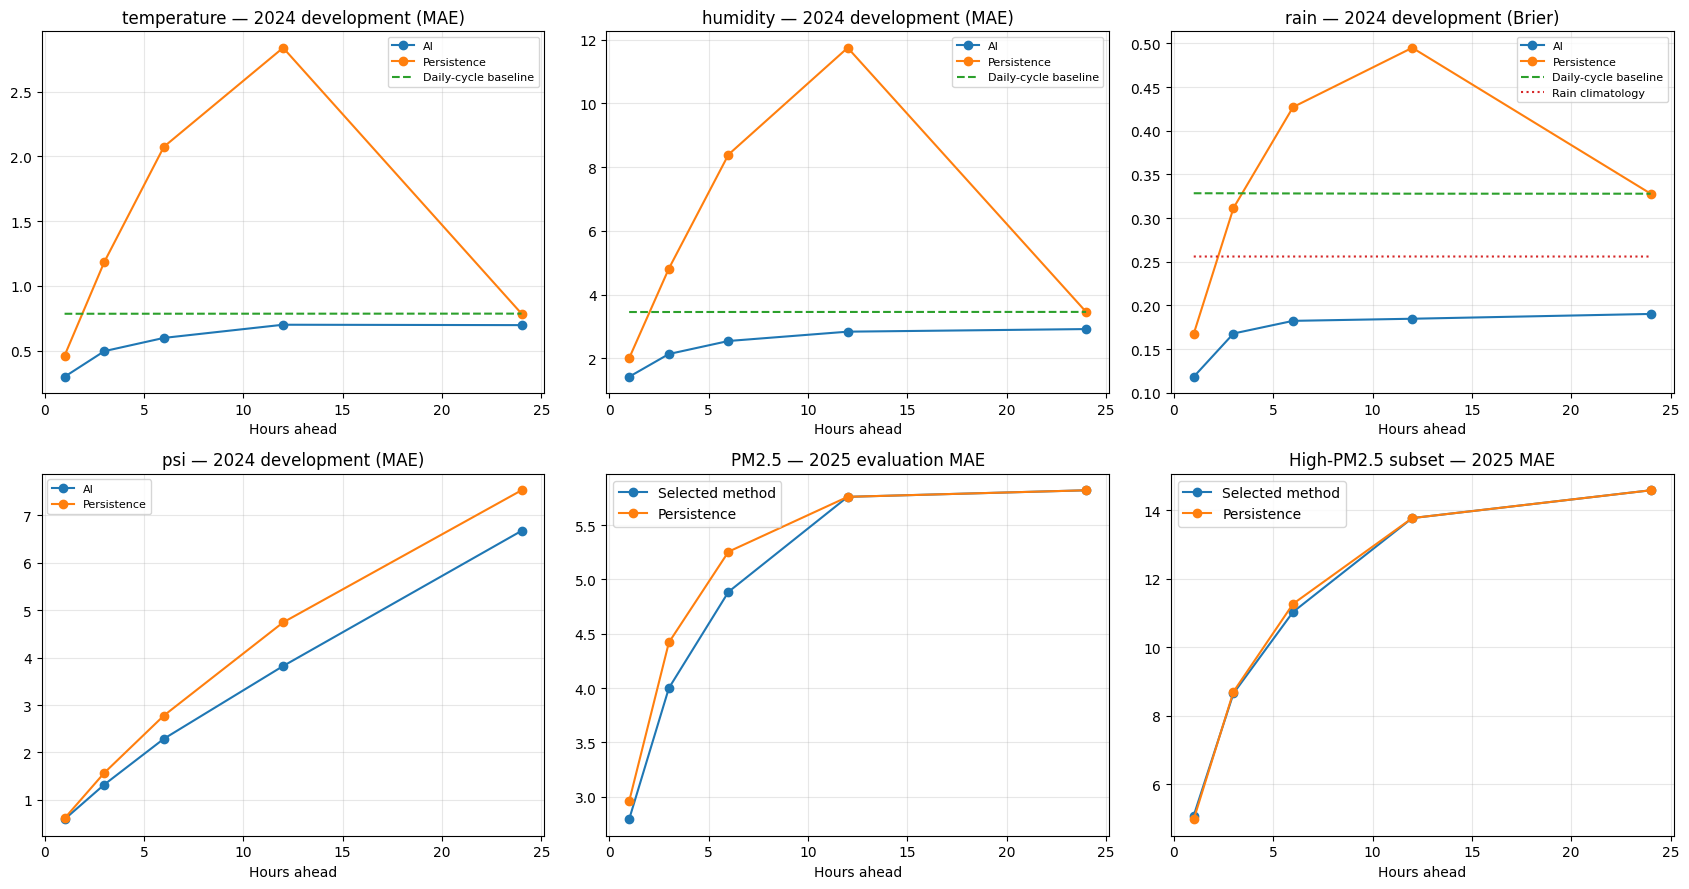

PM2.5 regional results — 2025:


,region,horizon_h,n,MAE,persistence_MAE,high_n,high_MAE,high_persistence_MAE,high_bias
0,central,1,8759,2.798,2.948,530,4.806,4.604,-3.945
1,central,3,8757,4.169,4.589,529,8.319,8.146,-7.848
2,central,6,8754,5.283,5.721,529,10.357,10.478,-9.669
3,central,12,8748,6.208,6.208,529,12.274,12.274,-11.268
4,central,24,8736,6.485,6.485,529,14.580,14.580,-13.688
5,east,1,8759,2.882,3.008,392,4.929,4.844,-3.798
6,east,3,8757,4.058,4.377,392,8.267,8.276,-7.716
7,east,6,8754,4.889,5.200,392,10.519,10.722,-10.105
8,east,12,8748,5.876,5.876,392,14.069,14.069,-13.855
9,east,24,8736,5.941,5.941,392,13.773,13.773,-13.140


Largest revised PM2.5 errors — 6h, 2025:


,region,origin_time_SGT,target_time_SGT,target,horizon_h,actual,predicted,persistence,absolute_error,signed_error
88443,north,2025-02-05 23:00:00,2025-02-06 05:00:00,pm25,6,67.0,13.520,13.0,53.480,-53.480
115976,west,2025-03-30 22:00:00,2025-03-31 04:00:00,pm25,6,62.0,13.201,12.0,48.799,-48.799
115982,west,2025-03-31 04:00:00,2025-03-31 10:00:00,pm25,6,9.0,55.343,62.0,46.343,46.343
88449,north,2025-02-06 05:00:00,2025-02-06 11:00:00,pm25,6,13.0,58.554,67.0,45.554,45.554
89714,north,2025-03-30 22:00:00,2025-03-31 04:00:00,pm25,6,53.0,7.858,6.0,45.142,-45.142
119489,west,2025-08-24 07:00:00,2025-08-24 13:00:00,pm25,6,6.0,50.969,57.0,44.969,44.969
115977,west,2025-03-30 23:00:00,2025-03-31 05:00:00,pm25,6,64.0,19.349,19.0,44.651,-44.651
115983,west,2025-03-31 05:00:00,2025-03-31 11:00:00,pm25,6,12.0,56.493,64.0,44.493,44.493
89715,north,2025-03-30 23:00:00,2025-03-31 05:00:00,pm25,6,56.0,12.851,12.0,43.149,-43.149
114706,west,2025-02-06 00:00:00,2025-02-06 06:00:00,pm25,6,58.0,15.205,16.0,42.795,-42.795


Largest weather/PSI errors — 6h, 2024 development:
temperature


,region,origin_time_SGT,target_time_SGT,target,horizon_h,actual,predicted,persistence,absolute_error
362899,east,2024-06-30 07:00:00,2024-06-30 13:00:00,temperature,6,26.4,30.288,26.4,3.888
354121,central,2024-06-30 07:00:00,2024-06-30 13:00:00,temperature,6,26.1,29.942,26.4,3.842
354120,central,2024-06-30 06:00:00,2024-06-30 12:00:00,temperature,6,25.9,29.697,25.5,3.797


... (2 outputs left out)

rain


,region,origin_time_SGT,target_time_SGT,target,horizon_h,actual,predicted,persistence,absolute_error
456111,north,2024-02-11 21:00:00,2024-02-12 03:00:00,rain,6,1.0,0.016,0.0,0.984
438555,central,2024-02-11 21:00:00,2024-02-12 03:00:00,rain,6,1.0,0.016,0.0,0.984
464889,south,2024-02-11 21:00:00,2024-02-12 03:00:00,rain,6,1.0,0.016,0.0,0.984


psi


,region,origin_time_SGT,target_time_SGT,target,horizon_h,actual,predicted,persistence,absolute_error
499758,north,2024-02-19 03:00:00,2024-02-19 09:00:00,psi,6,94.0,47.861,84.0,46.139
499757,north,2024-02-19 02:00:00,2024-02-19 08:00:00,psi,6,95.0,49.456,85.0,45.544
499756,north,2024-02-19 01:00:00,2024-02-19 07:00:00,psi,6,94.0,51.329,85.0,42.671


In [ ]:
development_metrics = weather_metrics[
    weather_metrics["stage"] == "development_2024"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()

for ax, target in zip(axes[:4], WEATHER_TARGETS):
    part = development_metrics[
        development_metrics["target"] == target
    ].sort_values("horizon_h")

    ax.plot(
        part["horizon_h"], part["AI_error"],
        marker="o", label="AI"
    )
    ax.plot(
        part["horizon_h"], part["persistence_error"],
        marker="o", label="Persistence"
    )

    if target != "psi":
        ax.plot(
            part["horizon_h"], part["daily_cycle_error"],
            linestyle="--", label="Daily-cycle baseline"
        )

    if target == "rain":
        ax.plot(
            part["horizon_h"],
            part["rain_climatology_Brier"],
            linestyle=":",
            label="Rain climatology"
        )

    ax.set_title(
        f"{target} — 2024 development "
        f"({'Brier' if target == 'rain' else 'MAE'})"
    )
    ax.set_xlabel("Hours ahead")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[4].plot(
    pm_results["horizon_h"], pm_results["MAE"],
    marker="o", label="Selected method"
)
axes[4].plot(
    pm_results["horizon_h"], pm_results["persistence_MAE"],
    marker="o", label="Persistence"
)
axes[4].set_title("PM2.5 — 2025 evaluation MAE")
axes[4].set_xlabel("Hours ahead")
axes[4].grid(alpha=0.3)
axes[4].legend()

axes[5].plot(
    pm_results["horizon_h"], pm_results["high_MAE"],
    marker="o", label="Selected method"
)
axes[5].plot(
    pm_results["horizon_h"],
    pm_results["high_persistence_MAE"],
    marker="o", label="Persistence"
)
axes[5].set_title("High-PM2.5 subset — 2025 MAE")
axes[5].set_xlabel("Hours ahead")
axes[5].grid(alpha=0.3)
axes[5].legend()

plt.tight_layout()
plt.show()

regional_rows = []

for (region, horizon), group in pm_test_predictions.groupby(
    ["region", "horizon_h"]
):
    threshold = pm_models[horizon]["threshold"]

    ai = concentration_errors(
        group["actual"].to_numpy(),
        group["predicted"].to_numpy(),
        threshold
    )
    baseline = concentration_errors(
        group["actual"].to_numpy(),
        group["persistence"].to_numpy(),
        threshold
    )

    regional_rows.append({
        "region": region,
        "horizon_h": horizon,
        "n": len(group),
        "MAE": ai["MAE"],
        "persistence_MAE": baseline["MAE"],
        "high_n": ai["high_n"],
        "high_MAE": ai["high_MAE"],
        "high_persistence_MAE": baseline["high_MAE"],
        "high_bias": ai["high_bias"]
    })

pm_regional_metrics = pd.DataFrame(regional_rows)

print("PM2.5 regional results — 2025:")
display(pm_regional_metrics.round(3))

failures = pm_test_predictions[
    pm_test_predictions["horizon_h"] == 6
].copy()

failures["absolute_error"] = (
    failures["predicted"] - failures["actual"]
).abs()

failures["signed_error"] = (
    failures["predicted"] - failures["actual"]
)

print("Largest revised PM2.5 errors — 6h, 2025:")
display(
    failures.sort_values(
        "absolute_error", ascending=False
    ).head(10).round(3)
)

print("Largest weather/PSI errors — 6h, 2024 development:")

for target in WEATHER_TARGETS:
    part = weather_replay[
        (weather_replay["target"] == target)
        & (weather_replay["horizon_h"] == 6)
    ].copy()

    part["absolute_error"] = (
        part["predicted"] - part["actual"]
    ).abs()

    print(target)
    display(
        part.sort_values(
            "absolute_error", ascending=False
        ).head(3).round(3)
    )

## Combined historical demo

The demo combines:
- Weather and PSI development predictions for 2024.
- Revised PM2.5 predictions for the same 2024 origin times.

PM2.5 models were selected using 2023.
The 2024 replay does not change their selection.

The demo shows historical predictions, not current forecasts.
Actual outcomes appear separately for comparison.

Weather values represent ERA5 grid conditions.
PM2.5 and PSI represent NEA regions.

The interface displays the PM2.5 method selected for each horizon,
including persistence when no AI candidate qualified.

Citizen and school suggestions use a demonstration rain threshold of 60%.
This threshold is not validated as a school decision policy.

In [ ]:
replay_predictions = pd.concat(
    [weather_replay, pm_replay],
    ignore_index=True
)

key_columns = [
    "region", "origin_time_SGT", "target", "horizon_h"
]

if replay_predictions.duplicated(key_columns).any():
    raise ValueError("Duplicate combined prediction keys.")

ALL_TARGETS = ["temperature", "humidity", "rain", "pm25", "psi"]

expected_pairs = {
    (target, horizon)
    for target in ALL_TARGETS
    for horizon in HORIZONS
}

demo_dates = {}

for region in REGIONS:
    part = replay_predictions[
        replay_predictions["region"] == region
    ]

    eligible = []

    for origin, group in part.groupby("origin_time_SGT"):
        if origin.hour != 8:
            continue

        pairs = set(zip(group["target"], group["horizon_h"]))

        if (
            pairs == expected_pairs
            and len(group) == len(expected_pairs)
        ):
            eligible.append(origin)

    if not eligible:
        raise ValueError(
            f"No complete 08:00 replay samples for {region}."
        )

    demo_dates[region] = sorted(eligible)

region_widget = widgets.Dropdown(
    options=REGIONS,
    value="central",
    description="Region:"
)

date_widget = widgets.Dropdown(
    options=[
        (str(t), t) for t in demo_dates["central"]
    ],
    description="Origin:",
    layout=widgets.Layout(width="440px")
)

audience_widget = widgets.ToggleButtons(
    options=["Citizens", "Schools"],
    description="Audience:"
)

demo_button = widgets.Button(
    description="Show historical predictions",
    button_style="primary"
)

demo_output = widgets.Output()


def update_region(change):
    if change["name"] == "value":
        date_widget.options = [
            (str(t), t)
            for t in demo_dates[change["new"]]
        ]


region_widget.observe(update_region, names="value")


def show_demo(_):
    with demo_output:
        clear_output(wait=True)

        region = region_widget.value
        origin = pd.Timestamp(date_widget.value)

        part = replay_predictions[
            (replay_predictions["region"] == region)
            & (replay_predictions["origin_time_SGT"] == origin)
        ]

        predictions = part.pivot(
            index="horizon_h",
            columns="target",
            values="predicted"
        ).reindex(HORIZONS)

        table = pd.DataFrame(index=predictions.index)
        table.index.name = "hours_ahead"

        table["target_time_SGT"] = [
            origin + pd.Timedelta(hours=h)
            for h in table.index
        ]

        table["temperature_C_ERA5"] = predictions["temperature"]
        table["humidity_%_ERA5"] = predictions["humidity"]
        table["rain_probability_%_ERA5"] = 100 * predictions["rain"]
        table["PM25_ug_m3_NEA"] = predictions["pm25"]
        table["PSI_NEA"] = predictions["psi"]

        table["PM25_method"] = [
            pm_models[h]["name"] for h in table.index
        ]

        if audience_widget.value == "Schools":
            table["suggestion"] = [
                "Prepare an indoor alternative."
                if probability >= 0.60
                else "Keep as an option; check official updates."
                for probability in predictions["rain"]
            ]
        else:
            table["suggestion"] = [
                "Prepare an umbrella or indoor alternative."
                if probability >= 0.60
                else "Keep as an option; check updates before leaving."
                for probability in predictions["rain"]
            ]

        print("SkyPlan SG — 2024 historical replay")
        print("This is not a current forecast.")
        print("Region:", region)
        print("Origin:", origin, "SGT")
        print("Weather represents ERA5 grid conditions.")

        display(table.round(2))

        actual = part.pivot(
            index="horizon_h",
            columns="target",
            values="actual"
        ).reindex(HORIZONS)

        print("\nHistorical outcomes — comparison only")
        print("Rain: 1 = rainy target hour; 0 = dry target hour.")
        display(actual.round(2))


demo_button.on_click(show_demo)

display(
    region_widget,
    date_widget,
    audience_widget,
    demo_button,
    demo_output
)

show_demo(None)

Dropdown(description='Region:', index=4, options=('north', 'south', 'east', 'west', 'central'), value='central…

Dropdown(description='Origin:', layout=Layout(width='440px'), options=(('2024-01-01 08:00:00', Timestamp('2024…

ToggleButtons(description='Audience:', options=('Citizens', 'Schools'), value='Citizens')

Button(button_style='primary', description='Show historical predictions', style=ButtonStyle())

Output()

## Conclusions

Complete this section using the actual results.

Report:
- Which weather/PSI horizons improve over persistence.
- Whether weather models also beat the daily-cycle baseline.
- Whether rain probabilities beat climatology.
- Which PM2.5 horizons select Ridge or persistence.
- Overall and high-PM2.5 performance in 2025.
- Regional differences and failure examples.

Do not describe persistence outputs as AI improvements.
Do not combine 2024 development scores and 2025 PM2.5 scores
into one overall final-test result.

### Remaining limitations
- Weather targets are reanalysis, not independent station measurements.
- Regional weather can share grid cells.
- No live input pipeline has been evaluated.
- PM2.5 deterioration can still be underestimated.
- High-concentration validation improvements may not generalise.
- PSI averaging windows make persistence strong at short horizons.
- School-specific exposure and activity outcomes have not been measured.

### Next steps
- Validate weather predictions against aligned NEA observations.
- Evaluate inputs actually available at prediction issuance.
- Test the planning interface with users.

### Sources and credits

NEA hourly PM2.5:
https://data.gov.sg/datasets/d_6c0d5fc34838b12472475fdb73c0af29/view

NEA historical PSI:
https://data.gov.sg/collections/2215/view

ERA5 through Open-Meteo:
https://open-meteo.com/en/docs/historical-weather-api

Open-Meteo terms:
https://open-meteo.com/en/terms

Libraries:
pandas, NumPy, requests, scikit-learn, Matplotlib, ipywidgets,
threadpoolctl.

AI assistance:
ChatGPT assisted with code generation, validation design,
and interpretation of development results.
The team must review, execute, and understand the implementation.

In [ ]:
manifest["periods"] = {
    "weather_PSI_training": "2020-2022",
    "rain_calibration": "2023-01-01 to 2023-06-30",
    "weather_PSI_validation": "2023-07-01 to 2023-12-31",
    "weather_PSI_development": "2024",
    "PM25_training": "2014-04 onward through 2022",
    "PM25_selection": "2023",
    "PM25_demo": "2024",
    "PM25_final_evaluation": "2025"
}

manifest["PM25_selected_methods"] = {
    str(h): {
        "name": pm_models[h]["name"],
        "blend": pm_models[h]["blend"],
        "high_threshold": pm_models[h]["threshold"]
    }
    for h in HORIZONS
}

manifest["limitations"] = [
    "Retrospective experiment; not a live forecast.",
    "Weather targets are ERA5 reanalysis.",
    "Requested regions may share weather grid cells.",
    "2024 has already been inspected and is development evaluation.",
    "PM2.5 2025 evaluation is separate from the 2024 demo.",
    "No school-specific safety policy has been validated."
]

manifest["saved_at_utc"] = pd.Timestamp.now(tz="UTC").isoformat()

exports = {
    "weather_PSI_metrics.csv": weather_metrics,
    "weather_PSI_sample_counts.csv": weather_samples,
    "PM25_validation_candidates_2023.csv": pm_validation,
    "PM25_final_evaluation_2025.csv": pm_results,
    "PM25_regional_evaluation_2025.csv": pm_regional_metrics,
    "PM25_sample_counts.csv": pm_samples,
    "PM25_predictions_2025.csv": pm_test_predictions,
    "combined_replay_predictions_2024.csv": replay_predictions,
    "weather_grid_coordinates.csv": grid_table,
    "source_quality_summary.csv": quality_table.reset_index()
}

for filename, frame in exports.items():
    frame.to_csv(ROOT / filename, index=False)

(ROOT / "data_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

zip_path = ROOT / "SkyPlan_complete_results.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for filename in [
        *exports.keys(),
        "data_manifest.json"
    ]:
        archive.write(ROOT / filename, arcname=filename)

print("Saved results:", zip_path.name)
print("Save your Colab notebook with all outputs visible as well.")

files.download(str(zip_path))

Saved results: SkyPlan_complete_results.zip
Save your Colab notebook with all outputs visible as well.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 1 — Save and restore trained models

Save:
- Trained weather and PSI models.
- Rain-probability calibrators.
- Selected PM2.5 models and persistence settings.
- Feature column names and feature-generation settings.
- Source metadata and software versions.
- Small historical snapshots and prediction-check inputs.

Reload the saved package and compare its predictions with the original
in-memory models.

Matching predictions demonstrate that serialization preserved the models.
They do not demonstrate live forecasting accuracy.

Historical snapshots are stored for reproducibility.
They are not current observations.

In [ ]:
import json
import hashlib
import zipfile
import platform
import importlib.metadata
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from google.colab import files

# Use the variables already computed in the full version of the Colab notebook.
# This cell does not perform model fitting or retraining.
required_variables = [
    "weather_models",
    "pm_models",
    "X_base",
    "X_pm",
    "data",
    "pm_v2",
    "manifest",
    "REGIONS",
    "HORIZONS"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Trained variables are not present in the current runtime:"
        + ", ".join(missing_variables)
        + "Consequently, the trained model cannot be reconstructed from the ZIP file alone."
        "Please execute this cell in the runtime where the training was performed."
    )

if set(weather_models) != {
    (target, horizon)
    for target in ["temperature", "humidity", "rain", "psi"]
    for horizon in HORIZONS
}:
    raise ValueError("Weather/PSI model collection is incomplete.")

if set(pm_models) != set(HORIZONS):
    raise ValueError("PM2.5 model collection is incomplete.")

SAVE_DIR = Path("/content/skyplan_model_package")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# A small amount of input used to verify consistency between saving and restoration.
weather_probe = (
    X_base.groupby(level="region", sort=False)
    .tail(3)
    .copy()
)

pm_probe_times = pm_v2.dropna().index[-12:]

if len(pm_probe_times) == 0:
    raise ValueError("No valid PM2.5 probe observations.")

pm_probe_features = X_pm.loc[pm_probe_times].copy()
pm_probe_current = pm_v2.loc[pm_probe_times, REGIONS].copy()


def make_weather_probe(base_features, model_bundle, horizon):
    result = base_features.copy()

    target_times = (
        result.index.get_level_values("time")
        + pd.Timedelta(hours=horizon)
    )

    result["target_hour_sin"] = np.sin(
        2 * np.pi * target_times.hour / 24
    )
    result["target_hour_cos"] = np.cos(
        2 * np.pi * target_times.hour / 24
    )

    expected_columns = model_bundle["feature_columns"]

    if not set(expected_columns).issubset(result.columns):
        raise ValueError("Weather probe features are incomplete.")

    return result[expected_columns]


def predict_saved_weather(model_bundle, features, target):
    estimator = model_bundle["model"]

    if target == "rain":
        raw_probability = estimator.predict_proba(features)[:, 1]

        clipped = np.clip(
            raw_probability, 1e-6, 1 - 1e-6
        )

        logits = np.log(
            clipped / (1 - clipped)
        ).reshape(-1, 1)

        prediction = (
            model_bundle["calibrator"]
            .predict_proba(logits)[:, 1]
        )

    else:
        prediction = estimator.predict(features)

        if target == "humidity":
            prediction = np.clip(prediction, 0, 100)
        elif target == "psi":
            prediction = np.maximum(prediction, 0)

    return prediction


def predict_saved_pm(model_bundle, features, current):
    current_array = current.to_numpy()

    if model_bundle["model"] is None:
        return current_array.copy()

    return np.maximum(
        0,
        current_array
        + model_bundle["blend"]
        * model_bundle["model"].predict(features)
    )


package = {
    "package_version": 1,
    "saved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "regions": list(REGIONS),
    "horizons": list(HORIZONS),

    "weather_models": weather_models,
    "pm_models": pm_models,

    "feature_columns": {
        "weather_base": list(X_base.columns),
        "pm25": list(X_pm.columns)
    },

    "feature_recipe": {
        "weather": {
            "lags_hours": [0, 1, 3, 6, 24],
            "rolling_windows_hours": [3, 24],
            "rolling_variables": [
                "temperature", "humidity", "rain_mm", "pm25"
            ],
            "wind_direction_encoding": "sin_cos",
            "annual_cycle_period": 365.25,
            "region_encoding": "one_hot",
            "target_hour_encoding": "sin_cos"
        },
        "pm25": {
            "lags_hours": [0, 1, 3, 6, 24, 48, 168],
            "rolling_windows_hours": [3, 24, 168],
            "change_hours": 3,
            "annual_cycle_period": 365.25,
            "region_order": list(REGIONS),
            "prediction": "current_plus_blended_change"
        }
    },

    # A snapshot of historical data. Not the latest observation.
    "historical_snapshots": {
        "weather_PSI": (
            data.groupby(level="region", sort=False)
            .tail(48)
            .copy()
        ),
        "pm25": pm_v2.tail(336).copy()
    },

    "roundtrip_check_inputs": {
        "weather_base": weather_probe,
        "pm25_features": pm_probe_features,
        "pm25_current": pm_probe_current
    },

    "data_manifest": manifest,

    "limitations": [
        "Historical snapshots are not live observations.",
        "Weather models were trained using ERA5 reanalysis.",
        "Multiple regions can share weather grid cells.",
        "Live-input performance has not been evaluated.",
        "Some PM2.5 horizons intentionally use persistence."
    ]
}

model_path = SAVE_DIR / "skyplan_models.joblib"
temporary_path = SAVE_DIR / "skyplan_models.part"

# Save to a temporary file, then confirm.
joblib.dump(package, temporary_path, compress=3)
temporary_path.replace(model_path)

# Reload the same file and compare the predictions.
restored = joblib.load(model_path)

check_rows = []

for (target, horizon), original_bundle in weather_models.items():
    restored_bundle = restored["weather_models"][(target, horizon)]

    features = make_weather_probe(
        weather_probe,
        original_bundle,
        horizon
    )

    before = predict_saved_weather(
        original_bundle, features, target
    )
    after = predict_saved_weather(
        restored_bundle, features, target
    )

    np.testing.assert_allclose(
        before, after,
        rtol=1e-12,
        atol=1e-12
    )

    check_rows.append({
        "component": target,
        "horizon_h": horizon,
        "max_absolute_difference": float(
            np.max(np.abs(before - after))
        ),
        "status": "PASS"
    })

for horizon, original_bundle in pm_models.items():
    restored_bundle = restored["pm_models"][horizon]

    before = predict_saved_pm(
        original_bundle,
        pm_probe_features,
        pm_probe_current
    )
    after = predict_saved_pm(
        restored_bundle,
        pm_probe_features,
        pm_probe_current
    )

    np.testing.assert_allclose(
        before, after,
        rtol=1e-12,
        atol=1e-12
    )

    check_rows.append({
        "component": "pm25",
        "horizon_h": horizon,
        "max_absolute_difference": float(
            np.max(np.abs(before - after))
        ),
        "status": "PASS"
    })

checks = pd.DataFrame(check_rows)
display(checks)

if len(checks) != 25 or not checks["status"].eq("PASS").all():
    raise RuntimeError("Model round-trip validation failed.")

# Record the restoration environment.
dependencies = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "joblib",
    "threadpoolctl"
]

versions = {
    name: importlib.metadata.version(name)
    for name in dependencies
}

requirements = "\n".join(
    f"{name}=={version}"
    for name, version in versions.items()
) + "\n"

(SAVE_DIR / "requirements_model.txt").write_text(requirements)

metadata = {
    "package_version": 1,
    "saved_at_utc": package["saved_at_utc"],
    "python_version": platform.python_version(),
    "dependency_versions": versions,
    "regions": list(REGIONS),
    "horizons": list(HORIZONS),
    "weather_model_count": len(weather_models),
    "pm25_horizon_count": len(pm_models),
    "pm25_methods": {
        str(h): pm_models[h]["name"]
        for h in HORIZONS
    },
    "historical_snapshot_latest_times": {
        "weather_PSI": str(
            package["historical_snapshots"]["weather_PSI"]
            .index.get_level_values("time").max()
        ),
        "pm25": str(
            package["historical_snapshots"]["pm25"].index.max()
        )
    },
    "model_sha256": hashlib.sha256(
        model_path.read_bytes()
    ).hexdigest(),
    "roundtrip_validation": "25 of 25 passed",
    "live_forecasting_validated": False
}

(SAVE_DIR / "model_metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

checks.to_csv(
    SAVE_DIR / "model_roundtrip_checks.csv",
    index=False
)

zip_path = SAVE_DIR / "SkyPlan_model_package.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for name in [
        "skyplan_models.joblib",
        "requirements_model.txt",
        "model_metadata.json",
        "model_roundtrip_checks.csv"
    ]:
        archive.write(SAVE_DIR / name, arcname=name)

print("Model saving and restoration checks PASSED.")
print("No models were retrained.")
print("Download:", zip_path.name)

files.download(str(zip_path))

,component,horizon_h,max_absolute_difference,status
0,temperature,1,0.0,PASS
1,humidity,1,0.0,PASS
2,rain,1,0.0,PASS
3,psi,1,0.0,PASS
4,temperature,3,0.0,PASS
5,humidity,3,0.0,PASS
6,rain,3,0.0,PASS
7,psi,3,0.0,PASS
8,temperature,6,0.0,PASS
9,humidity,6,0.0,PASS


Model saving and restoration checks PASSED.
No models were retrained.
Download: SkyPlan_model_package.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 2 — Connect recent data APIs

Retrieve:
- Regional hourly PM2.5 from NEA.
- Regional 24-hour PSI from NEA.
- Recent hourly modelled weather from Open-Meteo.

The revised PM2.5 model requires 169 consecutive hourly observations:
the current hour plus the previous 168 hours.

Weather and PSI models require at least 25 hourly input rows.

Checks:
- API response structure.
- Regional names.
- Timestamp timezone and hourly alignment.
- Duplicate and conflicting observations.
- Units, missing values, and basic physical limits.
- Latest observation age.
- A common recent origin time.
- Complete required history.

Do not fill missing observations with zero.
Do not substitute historical training snapshots for current inputs.

Open-Meteo's recent weather is model output, not station observations.
A recent valid timestamp does not prove that the underlying model
was issued recently.

These inputs differ from ERA5 training data.
This step validates acquisition and input completeness,
not live prediction accuracy.

In [ ]:
import json
import time
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import requests

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from IPython.display import display

LIVE_DIR = Path("/content/skyplan_live")
LIVE_DIR.mkdir(parents=True, exist_ok=True)

LIVE_REGIONS = ["north", "south", "east", "west", "central"]
LIVE_ZONE = "Asia/Singapore"

FETCH_TIME = pd.Timestamp.now(tz=LIVE_ZONE)
LAST_COMPLETED_HOUR = FETCH_TIME.floor("h")

# An operational upper limit set at one's own discretion. Not an official standard.
MAX_INPUT_AGE_HOURS = 3.0

# 9 days' worth of data, including today. Required for weekly-based historical features.
DATES = pd.date_range(
    FETCH_TIME.normalize() - pd.Timedelta(days=8),
    FETCH_TIME.normalize(),
    freq="D"
)

live_session = requests.Session()

live_session.mount(
    "https://",
    HTTPAdapter(max_retries=Retry(
        total=4,
        backoff_factor=2,
        status_forcelist=[429, 500, 502, 503, 504]
    ))
)

live_manifest = {
    "fetch_started_at": FETCH_TIME.isoformat(),
    "timezone": LIVE_ZONE,
    "max_input_age_hours": MAX_INPUT_AGE_HOURS,
    "sources": []
}


def live_json(url, params=None, filename=None):
    response = live_session.get(
        url,
        params=params,
        timeout=90
    )
    response.raise_for_status()
    payload = response.json()

    if filename:
        content = json.dumps(
            payload,
            ensure_ascii=False,
            sort_keys=True
        ).encode("utf-8")

        path = LIVE_DIR / filename
        path.write_bytes(content)

        live_manifest["sources"].append({
            "endpoint": url,
            "parameters": params or {},
            "retrieved_at": pd.Timestamp.now(
                tz=LIVE_ZONE
            ).isoformat(),
            "sha256": hashlib.sha256(content).hexdigest(),
            "filename": filename
        })

    return payload


def fetch_nea_history(endpoint_name, reading_field):
    endpoint = (
        "https://api-open.data.gov.sg/v2/real-time/api/"
        + endpoint_name
    )

    records = []

    for day in DATES:
        date_string = day.strftime("%Y-%m-%d")
        token = None
        seen_tokens = set()
        daily_count = 0

        print(
            f"Fetching NEA {endpoint_name}: {date_string}",
            flush=True
        )

        for page in range(50):
            params = {"date": date_string}

            if token:
                params["paginationToken"] = token

            payload = live_json(
                endpoint,
                params=params,
                filename=(
                    f"nea_{endpoint_name}_{date_string}_{page}.json"
                )
            )

            if payload.get("code") != 0:
                raise RuntimeError(
                    f"NEA {endpoint_name} returned an error: "
                    f"{payload.get('errorMsg')}"
                )

            response_data = payload.get("data")

            if not isinstance(response_data, dict):
                raise ValueError("Missing NEA data object.")

            items = response_data.get("items")

            if not isinstance(items, list):
                raise ValueError("Missing NEA items list.")

            for item in items:
                stamp = pd.Timestamp(item["timestamp"])
                updated = pd.Timestamp(item["updatedTimestamp"])

                if stamp.tzinfo is None or updated.tzinfo is None:
                    raise ValueError(
                        "NEA timestamps must include timezone."
                    )

                stamp = stamp.tz_convert(LIVE_ZONE)
                updated = updated.tz_convert(LIVE_ZONE)

                if stamp.minute != 0 or stamp.second != 0:
                    raise ValueError(
                        "Unexpected non-hourly NEA reading."
                    )

                readings = item.get(
                    "readings", {}
                ).get(reading_field)

                if not isinstance(readings, dict):
                    raise ValueError(
                        f"Missing reading field: {reading_field}"
                    )

                # Do not use times that occur after the start of the acquisition period as input.
                if stamp > LAST_COMPLETED_HOUR:
                    continue

                for region in LIVE_REGIONS:
                    value = pd.to_numeric(
                        readings.get(region),
                        errors="coerce"
                    )

                    records.append({
                        "time": stamp,
                        "updated_at": updated,
                        "region": region,
                        "value": value
                    })

                daily_count += 1

            token = response_data.get("paginationToken")

            if not token:
                break

            if token in seen_tokens:
                raise ValueError("Repeated pagination token.")

            seen_tokens.add(token)
            time.sleep(0.2)

        else:
            raise RuntimeError("Too many NEA pagination pages.")

        print("  Retrieved timestamp records:", daily_count)

    if not records:
        raise RuntimeError(f"No recent {endpoint_name} data.")

    frame = pd.DataFrame(records)

    if np.isinf(frame["value"].to_numpy()).any():
        raise ValueError("Infinite NEA reading.")

    if frame["value"].dropna().lt(0).any():
        raise ValueError("Negative NEA reading.")

    conflicts = frame.groupby(
        ["time", "region", "updated_at"]
    )["value"].nunique(dropna=False)

    if conflicts.gt(1).any():
        raise ValueError(
            "Conflicting NEA values at the same update time."
        )

    frame = (
        frame.sort_values("updated_at")
        .drop_duplicates(["time", "region"], keep="last")
    )

    wide = frame.pivot(
        index="time",
        columns="region",
        values="value"
    ).sort_index().reindex(columns=LIVE_REGIONS)

    # Standardized on a timezone-agnostic representation of SGT for common processing.
    wide.index = wide.index.tz_convert(
        LIVE_ZONE
    ).tz_localize(None)

    wide.index.name = "time"

    return wide, frame


live_pm25, live_pm25_records = fetch_nea_history(
    "pm25",
    "pm25_one_hourly"
)

live_psi, live_psi_records = fetch_nea_history(
    "psi",
    "psi_twenty_four_hourly"
)

print("\nLatest PM2.5 observations — µg/m³")
display(live_pm25.tail())

print("Latest regional 24-hour PSI")
display(live_psi.tail())

Fetching NEA pm25: 2026-11-06
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-07
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-08
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-09
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-10
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-11
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-12
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-13
  Retrieved timestamp records: 24
Fetching NEA pm25: 2026-11-14
  Retrieved timestamp records: 24
Fetching NEA psi: 2026-11-06
  Retrieved timestamp records: 24
Fetching NEA psi: 2026-11-07
  Retrieved timestamp records: 24
Fetching NEA psi: 2026-11-08
  Retrieved timestamp records: 24
Fetching NEA psi: 2026-11-09
  Retrieved timestamp records: 24
Fetching NEA psi: 2026-11-10
  Retrieved timestamp records: 24
Fetching NEA psi: 2026-11-11
  Retrieved timestamp records: 24
Fetching NEA psi: 2026-11-12
  Retrieved times

region,north,south,east,west,central
time,,,,,
2026-11-14 19:00:00,6,4,5,4,5
2026-11-14 20:00:00,6,5,6,15,7
2026-11-14 21:00:00,9,6,6,22,16
2026-11-14 22:00:00,14,7,7,14,14
2026-11-14 23:00:00,12,12,10,19,12


Latest regional 24-hour PSI


region,north,south,east,west,central
time,,,,,
2026-11-14 19:00:00,57,54,53,70,60
2026-11-14 20:00:00,57,54,53,69,59
2026-11-14 21:00:00,56,53,52,69,59
2026-11-14 22:00:00,55,53,52,68,59
2026-11-14 23:00:00,55,52,52,67,58


In [ ]:
# Regional representative coordinates for the NEA.
# These are not the coordinates of the school grounds or the observatory itself.
LIVE_COORDINATES = {
    "north": (1.41803, 103.82),
    "south": (1.29587, 103.82),
    "east": (1.35735, 103.94),
    "west": (1.35735, 103.70),
    "central": (1.35735, 103.82)
}

LIVE_WEATHER_VARIABLES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_direction_10m",
    "pressure_msl",
    "cloud_cover"
]

LIVE_WEATHER_UNITS = {
    "temperature_2m": "°C",
    "relative_humidity_2m": "%",
    "precipitation": "mm",
    "wind_speed_10m": "km/h",
    "wind_direction_10m": "°",
    "pressure_msl": "hPa",
    "cloud_cover": "%"
}

weather_params = {
    "latitude": ",".join(
        str(LIVE_COORDINATES[r][0])
        for r in LIVE_REGIONS
    ),
    "longitude": ",".join(
        str(LIVE_COORDINATES[r][1])
        for r in LIVE_REGIONS
    ),
    "hourly": ",".join(LIVE_WEATHER_VARIABLES),
    "past_days": 9,
    "forecast_days": 2,
    "timezone": LIVE_ZONE,
    "wind_speed_unit": "kmh"
}

print("Fetching recent Open-Meteo weather...", flush=True)

weather_payload = live_json(
    "https://api.open-meteo.com/v1/forecast",
    params=weather_params,
    filename="open_meteo_recent_weather.json"
)

if (
    not isinstance(weather_payload, list)
    or len(weather_payload) != len(LIVE_REGIONS)
):
    raise ValueError(
        "Unexpected multiple-location weather response."
    )

cutoff_naive = LAST_COMPLETED_HOUR.tz_localize(None)

live_weather_by_region = {}
live_grid_rows = []

for region, location in zip(
    LIVE_REGIONS,
    weather_payload
):
    if location.get("utc_offset_seconds") != 28800:
        raise ValueError("Unexpected weather timezone.")

    units = location.get("hourly_units", {})

    for variable, expected_unit in LIVE_WEATHER_UNITS.items():
        if units.get(variable) != expected_unit:
            raise ValueError(
                f"Unexpected unit: {variable}={units.get(variable)}"
            )

    frame = pd.DataFrame(location["hourly"])
    frame["time"] = pd.to_datetime(
        frame["time"], errors="raise"
    )

    frame = (
        frame.set_index("time")[LIVE_WEATHER_VARIABLES]
        .astype(float)
        .sort_index()
    )

    if frame.index.has_duplicates:
        raise ValueError("Duplicate weather timestamps.")

    if not (
        (frame.index.minute == 0)
        & (frame.index.second == 0)
    ).all():
        raise ValueError("Unexpected weather time interval.")

    # Do not mix API-generated future forecasts into the historical input data for your own custom models.
    frame = frame.loc[frame.index <= cutoff_naive].copy()

    if frame.empty:
        raise ValueError("No recent weather input rows.")

    if np.isinf(frame.to_numpy()).any():
        raise ValueError("Infinite weather values.")

    for column in ["relative_humidity_2m", "cloud_cover"]:
        if not frame[column].dropna().between(0, 100).all():
            raise ValueError(f"Invalid {column}.")

    if not frame["wind_direction_10m"].dropna().between(0, 360).all():
        raise ValueError("Invalid wind direction.")

    if (
        frame["precipitation"].dropna().lt(0).any()
        or frame["wind_speed_10m"].dropna().lt(0).any()
        or frame["pressure_msl"].dropna().le(0).any()
        or frame["temperature_2m"].dropna().le(-273.15).any()
    ):
        raise ValueError("Invalid weather values.")

    frame = frame.rename(columns={
        "temperature_2m": "temperature",
        "relative_humidity_2m": "humidity",
        "precipitation": "rain_mm"
    })

    live_weather_by_region[region] = frame

    live_grid_rows.append({
        "region": region,
        "requested_latitude": LIVE_COORDINATES[region][0],
        "requested_longitude": LIVE_COORDINATES[region][1],
        "returned_latitude": location["latitude"],
        "returned_longitude": location["longitude"],
        "source": "Open-Meteo Forecast API",
        "source_type": "model_output",
        "underlying_model_issue_time": "not verified"
    })

live_grid_table = pd.DataFrame(live_grid_rows)

display(live_grid_table)

print("Recent Central weather — model output, not station observations")
display(live_weather_by_region["central"].tail())

Fetching recent Open-Meteo weather...


,region,requested_latitude,requested_longitude,returned_latitude,returned_longitude,source,source_type,underlying_model_issue_time
0,north,1.41803,103.82,1.441125,103.813290,Open-Meteo Forecast API,model_output,not verified
1,south,1.29587,103.82,1.300527,103.791470,Open-Meteo Forecast API,model_output,not verified
2,east,1.35735,103.94,1.370826,103.944660,Open-Meteo Forecast API,model_output,not verified
3,west,1.35735,103.70,1.370826,103.731224,Open-Meteo Forecast API,model_output,not verified
4,central,1.35735,103.82,1.370826,103.802370,Open-Meteo Forecast API,model_output,not verified


Recent Central weather — model output, not station observations


,temperature,humidity,rain_mm,wind_speed_10m,wind_direction_10m,pressure_msl,cloud_cover
time,,,,,,,
2026-11-14 19:00:00,26.7,92.0,0.0,3.0,284.0,1010.6,99.0
2026-11-14 20:00:00,26.0,96.0,0.0,5.1,252.0,1011.5,99.0
2026-11-14 21:00:00,25.6,97.0,0.0,4.8,250.0,1012.6,100.0
2026-11-14 22:00:00,25.3,97.0,0.0,2.8,281.0,1013.3,94.0
2026-11-14 23:00:00,24.9,99.0,0.0,4.0,321.0,1013.5,36.0


In [ ]:
LIVE_INPUTS_READY = False
live_origin = None

now_naive = pd.Timestamp.now(
    tz=LIVE_ZONE
).tz_localize(None)

report_rows = []


def add_status(source, region, frame, columns):
    complete = frame[columns].dropna()

    if complete.empty:
        latest = pd.NaT
        age = np.nan
        fresh = False
    else:
        latest = complete.index.max()
        age = (
            now_naive - latest
        ).total_seconds() / 3600

        fresh = 0 <= age <= MAX_INPUT_AGE_HOURS

    report_rows.append({
        "source": source,
        "region": region,
        "latest_valid_time_SGT": latest,
        "age_hours": age,
        "within_age_limit": fresh
    })


for region in LIVE_REGIONS:
    add_status(
        "NEA PM2.5",
        region,
        live_pm25,
        [region]
    )

    add_status(
        "NEA PSI",
        region,
        live_psi,
        [region]
    )

    weather = live_weather_by_region[region]

    add_status(
        "Open-Meteo modelled weather",
        region,
        weather,
        list(weather.columns)
    )

live_report = pd.DataFrame(report_rows)

print("Source freshness report")
print("Age refers to valid time, not model issuance time.")
display(live_report.round(2))

# Find the most recent common timestamp for which data exists across all regions and all categories.
possible_origins = pd.date_range(
    cutoff_naive - pd.Timedelta(hours=3),
    cutoff_naive,
    freq="h"
)

eligible_origins = []

for candidate in possible_origins:
    age = (
        now_naive - candidate
    ).total_seconds() / 3600

    if not 0 <= age <= MAX_INPUT_AGE_HOURS:
        continue

    pm_current = live_pm25.reindex([candidate])
    psi_current = live_psi.reindex([candidate])

    current_complete = (
        pm_current.notna().all().all()
        and psi_current.notna().all().all()
    )

    for region in LIVE_REGIONS:
        weather_row = live_weather_by_region[region].reindex(
            [candidate]
        )

        current_complete = (
            current_complete
            and weather_row.notna().all().all()
        )

    if current_complete:
        eligible_origins.append(candidate)

if not eligible_origins:
    raise RuntimeError(
       "There is no recent common input timestamp."
       "Please check the table above for outdated or missing data."
       "It has not been replaced with historical training data."
    )

live_origin = max(eligible_origins)

pm_history_index = pd.date_range(
    live_origin - pd.Timedelta(hours=168),
    live_origin,
    freq="h"
)

weather_history_index = pd.date_range(
    live_origin - pd.Timedelta(hours=24),
    live_origin,
    freq="h"
)

pm_required = live_pm25.reindex(pm_history_index)
psi_required = live_psi.reindex(weather_history_index)

history_rows = []

for region in LIVE_REGIONS:
    weather_required = live_weather_by_region[region].reindex(
        weather_history_index
    )

    pm_missing = int(pm_required[region].isna().sum())
    psi_missing = int(psi_required[region].isna().sum())
    weather_missing = int(
        weather_required.isna().sum().sum()
    )

    history_rows.append({
        "region": region,
        "PM25_required_hours": 169,
        "PM25_missing_hours": pm_missing,
        "PSI_required_hours": 25,
        "PSI_missing_hours": psi_missing,
        "weather_required_hours": 25,
        "weather_missing_cells": weather_missing,
        "ready": (
            pm_missing == 0
            and psi_missing == 0
            and weather_missing == 0
        )
    })

live_history_report = pd.DataFrame(history_rows)

print("Required-history report")
display(live_history_report)

LIVE_INPUTS_READY = bool(
    live_history_report["ready"].all()
)

live_manifest["selected_origin_SGT"] = live_origin.isoformat()
live_manifest["input_history_complete"] = LIVE_INPUTS_READY
live_manifest["weather_source_change"] = (
    "ERA5 training -> Open-Meteo Forecast API inputs"
)
live_manifest["live_forecast_accuracy_validated"] = False

live_report.to_csv(
    LIVE_DIR / "freshness_report.csv",
    index=False
)

live_history_report.to_csv(
    LIVE_DIR / "history_report.csv",
    index=False
)

(LIVE_DIR / "live_data_manifest.json").write_text(
    json.dumps(live_manifest, indent=2)
)

if not LIVE_INPUTS_READY:
    raise RuntimeError(
        "There are gaps in the required historical data."
        "Prediction will not be performed yet."
        "Missing values ​​have not been filled with zeros or older training data."
    )

# Create a current history panel to be used in the next step.
live_panel_parts = []

for region in LIVE_REGIONS:
    frame = live_weather_by_region[region].reindex(
        pm_history_index
    ).copy()

    frame["pm25"] = live_pm25.reindex(
        pm_history_index
    )[region]

    frame["psi"] = live_psi.reindex(
        pm_history_index
    )[region]

    frame["region"] = region
    frame.index.name = "time"

    live_panel_parts.append(frame.reset_index())

live_panel = (
    pd.concat(live_panel_parts, ignore_index=True)
    .set_index(["region", "time"])
    .sort_index()
)

print("STEP 2 PASSED")
print("Common prediction origin:", live_origin, "SGT")
print("Required recent input history is complete.")
print("No models were retrained.")
print("Live forecasting accuracy remains unvalidated.")

Source freshness report
Age refers to valid time, not model issuance time.


,source,region,latest_valid_time_SGT,age_hours,within_age_limit
0,NEA PM2.5,north,2026-11-14 23:00:00,0.04,True
1,NEA PSI,north,2026-11-14 23:00:00,0.04,True
2,Open-Meteo modelled weather,north,2026-11-14 23:00:00,0.04,True
3,NEA PM2.5,south,2026-11-14 23:00:00,0.04,True
4,NEA PSI,south,2026-11-14 23:00:00,0.04,True
5,Open-Meteo modelled weather,south,2026-11-14 23:00:00,0.04,True
6,NEA PM2.5,east,2026-11-14 23:00:00,0.04,True
7,NEA PSI,east,2026-11-14 23:00:00,0.04,True
8,Open-Meteo modelled weather,east,2026-11-14 23:00:00,0.04,True
9,NEA PM2.5,west,2026-11-14 23:00:00,0.04,True


Required-history report


,region,PM25_required_hours,PM25_missing_hours,PSI_required_hours,PSI_missing_hours,weather_required_hours,weather_missing_cells,ready
0,north,169,0,25,0,25,0,True
1,south,169,0,25,0,25,0,True
2,east,169,0,25,0,25,0,True
3,west,169,0,25,0,25,0,True
4,central,169,0,25,0,25,0,True


STEP 2 PASSED
Common prediction origin: 2026-11-14 23:00:00 SGT
Required recent input history is complete.
No models were retrained.
Live forecasting accuracy remains unvalidated.


## Step 3 — Generate experimental live predictions

Load the saved models and rebuild their input features from recent data.

Before prediction:
1. Verify the model file hash and software versions.
2. Rebuild historical check features.
3. Compare them with the feature values saved during model export.
4. Check recent input completeness and age.
5. Generate predictions.

Weather and PSI models now receive Open-Meteo Forecast API weather
instead of ERA5 training inputs. These outputs are experimental.

PM2.5 uses recent NEA concentrations.
The selected method is shown for every horizon.
Persistence outputs are explicitly labelled.

Previous retrospective accuracy does not establish current live accuracy.

Rain probability refers to the hour ending at the target time.
These predictions do not determine whether school activities are safe.

In [ ]:
import json
import hashlib
import importlib.metadata
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from IPython.display import display
from threadpoolctl import threadpool_limits

if not globals().get("LIVE_INPUTS_READY", False):
    raise RuntimeError(
        'Please perform Step 2 first and confirm that "STEP 2 PASSED" is displayed.'
    )

PACKAGE_DIR = Path("/content/skyplan_model_package")
MODEL_FILE = PACKAGE_DIR / "skyplan_models.joblib"
METADATA_FILE = PACKAGE_DIR / "model_metadata.json"

if not MODEL_FILE.exists() or not METADATA_FILE.exists():
    raise RuntimeError(
        "The model saved in Step 1 cannot be found."
        "Please continue using the same runtime where the model was saved."
        )

model_metadata = json.loads(METADATA_FILE.read_text())

actual_hash = hashlib.sha256(
    MODEL_FILE.read_bytes()
).hexdigest()

if actual_hash != model_metadata["model_sha256"]:
    raise ValueError("Model file hash mismatch.")

# Avoid silent loading across different versions.
version_mismatches = []

for dependency, expected_version in (
    model_metadata["dependency_versions"].items()
):
    installed_version = importlib.metadata.version(dependency)

    if installed_version != expected_version:
        version_mismatches.append({
            "dependency": dependency,
            "saved": expected_version,
            "installed": installed_version
        })

if version_mismatches:
    display(pd.DataFrame(version_mismatches))
    raise RuntimeError(
        "The library version differs from the one used at the time of saving."
        "Please check the `requirements_model.txt` file in the model package."
    )

# Load the model that you saved in Step 1.
live_model_package = joblib.load(MODEL_FILE)

MODEL_REGIONS = live_model_package["regions"]
MODEL_HORIZONS = live_model_package["horizons"]

if MODEL_REGIONS != LIVE_REGIONS:
    raise ValueError("Model and live-data region orders differ.")

WEATHER_CORE = [
    "temperature",
    "humidity",
    "rain_mm",
    "wind_speed_10m",
    "pressure_msl",
    "cloud_cover",
    "pm25",
    "psi"
]


def rebuild_weather_features(panel, regions):
    required_columns = set(
        WEATHER_CORE + ["wind_direction_10m"]
    )

    if not required_columns.issubset(panel.columns):
        raise ValueError("Missing weather feature source columns.")

    parts = []

    for region in regions:
        source = (
            panel.xs(region, level="region")
            .sort_index()
        )

        if source.index.has_duplicates:
            raise ValueError("Duplicate weather history timestamps.")

        features = pd.DataFrame(index=source.index)

        for column in WEATHER_CORE:
            for lag in [0, 1, 3, 6, 24]:
                features[f"{column}_lag{lag}"] = (
                    source[column].shift(lag)
                )

        for column in [
            "temperature", "humidity", "rain_mm", "pm25"
        ]:
            for window in [3, 24]:
                features[f"{column}_mean{window}"] = (
                    source[column]
                    .rolling(window, min_periods=window)
                    .mean()
                )

        radians = np.deg2rad(source["wind_direction_10m"])

        features["wind_sin"] = np.sin(radians)
        features["wind_cos"] = np.cos(radians)

        features["hour_sin"] = np.sin(
            2 * np.pi * source.index.hour / 24
        )
        features["hour_cos"] = np.cos(
            2 * np.pi * source.index.hour / 24
        )
        features["year_sin"] = np.sin(
            2 * np.pi * source.index.dayofyear / 365.25
        )
        features["year_cos"] = np.cos(
            2 * np.pi * source.index.dayofyear / 365.25
        )

        for category in regions:
            features[f"region_{category}"] = float(
                region == category
            )

        features.index.name = "time"
        features["region"] = region

        parts.append(
            features.reset_index()
            .set_index(["region", "time"])
        )

    return pd.concat(parts).sort_index().astype(float)


def rebuild_pm_features(wide, regions):
    source = wide[regions].sort_index()
    features = pd.DataFrame(index=source.index)

    for region in regions:
        for lag in [0, 1, 3, 6, 24, 48, 168]:
            features[f"{region}_lag{lag}"] = (
                source[region].shift(lag)
            )

        for window in [3, 24, 168]:
            features[f"{region}_mean{window}"] = (
                source[region]
                .rolling(window, min_periods=window)
                .mean()
            )

        features[f"{region}_change3"] = (
            source[region] - source[region].shift(3)
        )

    for name, values, period in [
        ("hour", source.index.hour, 24),
        ("year", source.index.dayofyear, 365.25)
    ]:
        features[name + "_sin"] = np.sin(
            2 * np.pi * values / period
        )
        features[name + "_cos"] = np.cos(
            2 * np.pi * values / period
        )

    return features


def check_feature_schema(frame, expected_columns):
    if (
        len(frame.columns) != len(expected_columns)
        or set(frame.columns) != set(expected_columns)
    ):
        missing = set(expected_columns) - set(frame.columns)
        extra = set(frame.columns) - set(expected_columns)

        raise ValueError(
            f"Feature schema mismatch. Missing={missing}, extra={extra}"
        )

    return frame[expected_columns]


# Reconstruct feature values ​​from stored history.
snapshots = live_model_package["historical_snapshots"]
check_inputs = live_model_package["roundtrip_check_inputs"]

historical_weather_features = rebuild_weather_features(
    snapshots["weather_PSI"],
    MODEL_REGIONS
)

expected_weather_features = check_inputs["weather_base"]

historical_weather_features = check_feature_schema(
    historical_weather_features,
    live_model_package["feature_columns"]["weather_base"]
)

np.testing.assert_allclose(
    historical_weather_features.loc[
        expected_weather_features.index,
        expected_weather_features.columns
    ].to_numpy(),
    expected_weather_features.to_numpy(),
    rtol=1e-10,
    atol=1e-9,
    equal_nan=True
)

historical_pm_features = rebuild_pm_features(
    snapshots["pm25"],
    MODEL_REGIONS
)

expected_pm_features = check_inputs["pm25_features"]

historical_pm_features = check_feature_schema(
    historical_pm_features,
    live_model_package["feature_columns"]["pm25"]
)

np.testing.assert_allclose(
    historical_pm_features.loc[
        expected_pm_features.index,
        expected_pm_features.columns
    ].to_numpy(),
    expected_pm_features.to_numpy(),
    rtol=1e-10,
    atol=1e-9,
    equal_nan=True
)

print("Model file check: PASS")
print("Software version check: PASS")
print("Weather feature reconstruction: PASS")
print("PM2.5 feature reconstruction: PASS")

Model file check: PASS
Software version check: PASS
Weather feature reconstruction: PASS
PM2.5 feature reconstruction: PASS


In [ ]:
# Double-check whether too much time has passed since Step 2.
prediction_started_at = pd.Timestamp.now(
    tz="Asia/Singapore"
)

origin = pd.Timestamp(live_origin)

if origin.tzinfo is not None:
    origin = origin.tz_convert(
        "Asia/Singapore"
    ).tz_localize(None)

origin_age_hours = (
    prediction_started_at.tz_localize(None) - origin
).total_seconds() / 3600

if not 0 <= origin_age_hours <= MAX_INPUT_AGE_HOURS:
    raise RuntimeError(
        f"The input time is outdated:{origin_age_hours:.2f} hours ago."
        "Please re-execute the API retrieval step (Step 2)."
    )

# Align it explicitly with a continuous 169-hour period.
required_index = pd.date_range(
    origin - pd.Timedelta(hours=168),
    origin,
    freq="h"
)

recent_pm = live_pm25.reindex(
    index=required_index,
    columns=MODEL_REGIONS
)

if recent_pm.isna().any().any():
    raise ValueError("Required PM2.5 history is incomplete.")

recent_panel_parts = []

for region in MODEL_REGIONS:
    source = live_panel.xs(
        region, level="region"
    ).reindex(required_index).copy()

    source.index.name = "time"
    source["region"] = region

    recent_panel_parts.append(
        source.reset_index().set_index(["region", "time"])
    )

recent_panel = pd.concat(
    recent_panel_parts
).sort_index()

weather_features = rebuild_weather_features(
    recent_panel,
    MODEL_REGIONS
)

weather_features = check_feature_schema(
    weather_features,
    live_model_package["feature_columns"]["weather_base"]
)

pm_features = rebuild_pm_features(
    recent_pm,
    MODEL_REGIONS
)

pm_features = check_feature_schema(
    pm_features,
    live_model_package["feature_columns"]["pm25"]
)

weather_origin_index = pd.MultiIndex.from_tuples(
    [(region, origin) for region in MODEL_REGIONS],
    names=["region", "time"]
)

weather_origin_features = weather_features.loc[
    weather_origin_index
].copy()

pm_origin_features = pm_features.loc[[origin]].copy()
pm_current = recent_pm.loc[[origin], MODEL_REGIONS].to_numpy()

# In this instance, we will limit the scope to inputs that contain no missing features.
if (
    not np.isfinite(weather_origin_features.to_numpy()).all()
    or not np.isfinite(pm_origin_features.to_numpy()).all()
    or not np.isfinite(pm_current).all()
):
    raise ValueError(
        "There are missing or infinite values ​​in the feature data at the time of prediction."
        "Stopping predictions."
    )


def predict_weather_component(bundle, features, target):
    if target == "rain":
        raw_probability = (
            bundle["model"].predict_proba(features)[:, 1]
        )

        clipped = np.clip(
            raw_probability, 1e-6, 1 - 1e-6
        )

        logits = np.log(
            clipped / (1 - clipped)
        ).reshape(-1, 1)

        return bundle["calibrator"].predict_proba(
            logits
        )[:, 1]

    prediction = bundle["model"].predict(features)

    if target == "humidity":
        prediction = np.clip(prediction, 0, 100)
    elif target == "psi":
        prediction = np.maximum(prediction, 0)

    return prediction


prediction_rows = []

with threadpool_limits(limits=2):
    for horizon in MODEL_HORIZONS:
        target_time = origin + pd.Timedelta(hours=horizon)

        X_weather = weather_origin_features.copy()

        X_weather["target_hour_sin"] = np.sin(
            2 * np.pi * target_time.hour / 24
        )
        X_weather["target_hour_cos"] = np.cos(
            2 * np.pi * target_time.hour / 24
        )

        weather_outputs = {}

        for target in [
            "temperature", "humidity", "rain", "psi"
        ]:
            bundle = live_model_package[
                "weather_models"
            ][(target, horizon)]

            expected_columns = bundle["feature_columns"]

            if set(X_weather.columns) != set(expected_columns):
                raise ValueError(
                    f"Model input mismatch: {target}, {horizon}h"
                )

            prediction = predict_weather_component(
                bundle,
                X_weather[expected_columns],
                target
            )

            if not np.isfinite(prediction).all():
                raise ValueError(
                    f"Non-finite prediction: {target}, {horizon}h"
                )

            weather_outputs[target] = prediction

        pm_bundle = live_model_package[
            "pm_models"
        ][horizon]

        if pm_bundle["model"] is None:
            pm_prediction = pm_current.copy()
        else:
            change = pm_bundle["model"].predict(
                pm_origin_features
            )

            pm_prediction = np.maximum(
                0,
                pm_current + pm_bundle["blend"] * change
            )

        if not np.isfinite(pm_prediction).all():
            raise ValueError("Non-finite PM2.5 prediction.")

        for column_index, region in enumerate(MODEL_REGIONS):
            prediction_rows.append({
                "region": region,
                "origin_time_SGT": origin,
                "horizon_h": horizon,
                "target_time_SGT": target_time,
                "rain_interval_start_SGT": (
                    target_time - pd.Timedelta(hours=1)
                ),
                "temperature_C": float(
                    weather_outputs["temperature"][column_index]
                ),
                "humidity_%": float(
                    weather_outputs["humidity"][column_index]
                ),
                "rain_probability_%": float(
                    100 * weather_outputs["rain"][column_index]
                ),
                "PM25_ug_m3": float(
                    pm_prediction[0, column_index]
                ),
                "PSI": float(
                    weather_outputs["psi"][column_index]
                ),
                "PM25_method": pm_bundle["name"],
                "status": "experimental_live_prediction"
            })

live_predictions = pd.DataFrame(prediction_rows).sort_values(
    ["region", "horizon_h"]
).reset_index(drop=True)

if (
    len(live_predictions)
    != len(MODEL_REGIONS) * len(MODEL_HORIZONS)
):
    raise ValueError("Incomplete prediction output.")

if live_predictions.duplicated(
    ["region", "origin_time_SGT", "horizon_h"]
).any():
    raise ValueError("Duplicate prediction rows.")

print("STEP 3 PASSED")
print("Prediction origin:", origin, "SGT")
print(f"Origin age: {origin_age_hours:.2f} hours")
print("No models were retrained.")
print("These are experimental predictions, not validated live accuracy.")

display(live_predictions.round(2))

STEP 3 PASSED
Prediction origin: 2026-11-14 23:00:00 SGT
Origin age: 0.10 hours
No models were retrained.
These are experimental predictions, not validated live accuracy.


,region,origin_time_SGT,horizon_h,target_time_SGT,rain_interval_start_SGT,temperature_C,humidity_%,rain_probability_%,PM25_ug_m3,PSI,PM25_method,status
0,central,2026-11-14 23:00:00,1,2026-11-15 00:00:00,2026-11-14 23:00:00,24.86,94.77,13.13,13.45,57.69,"Ridge weight=4.0, blend=0.5",experimental_live_prediction
1,central,2026-11-14 23:00:00,3,2026-11-15 02:00:00,2026-11-15 01:00:00,24.64,94.02,20.61,14.85,56.83,"Ridge weight=4.0, blend=0.5",experimental_live_prediction
2,central,2026-11-14 23:00:00,6,2026-11-15 05:00:00,2026-11-15 04:00:00,24.49,93.78,34.58,14.15,55.56,"Ridge weight=4.0, blend=0.25",experimental_live_prediction
3,central,2026-11-14 23:00:00,12,2026-11-15 11:00:00,2026-11-15 10:00:00,28.67,78.04,71.46,12.00,52.83,Persistence,experimental_live_prediction
4,central,2026-11-14 23:00:00,24,2026-11-15 23:00:00,2026-11-15 22:00:00,25.24,91.51,22.98,12.00,52.57,Persistence,experimental_live_prediction
5,east,2026-11-14 23:00:00,1,2026-11-15 00:00:00,2026-11-14 23:00:00,26.28,92.00,7.67,10.78,51.38,"Ridge weight=4.0, blend=0.5",experimental_live_prediction
6,east,2026-11-14 23:00:00,3,2026-11-15 02:00:00,2026-11-15 01:00:00,25.93,92.59,20.76,12.20,49.65,"Ridge weight=4.0, blend=0.5",experimental_live_prediction
7,east,2026-11-14 23:00:00,6,2026-11-15 05:00:00,2026-11-15 04:00:00,25.72,92.84,40.66,12.10,45.67,"Ridge weight=4.0, blend=0.25",experimental_live_prediction
8,east,2026-11-14 23:00:00,12,2026-11-15 11:00:00,2026-11-15 10:00:00,29.34,78.25,77.57,10.00,40.28,Persistence,experimental_live_prediction
9,east,2026-11-14 23:00:00,24,2026-11-15 23:00:00,2026-11-15 22:00:00,26.56,89.80,26.06,10.00,43.80,Persistence,experimental_live_prediction


In [ ]:
import ipywidgets as widgets
from IPython.display import clear_output

live_region_widget = widgets.Dropdown(
    options=MODEL_REGIONS,
    value="central",
    description="Region:"
)

live_prediction_output = widgets.Output()


def display_live_region(change=None):
    with live_prediction_output:
        clear_output(wait=True)

        region = live_region_widget.value

        selected = live_predictions[
            live_predictions["region"] == region
        ].copy()

        print("SkyPlan SG — experimental live predictions")
        print("Region:", region)
        print("Origin:", origin, "SGT")
        print(
            "Weather inputs differ from ERA5 training data; "
            "live accuracy is unvalidated."
        )

        display(selected[[
            "horizon_h",
            "target_time_SGT",
            "temperature_C",
            "humidity_%",
            "rain_probability_%",
            "PM25_ug_m3",
            "PSI",
            "PM25_method"
        ]].round(2))


live_region_widget.observe(
    display_live_region,
    names="value"
)

display(live_region_widget, live_prediction_output)
display_live_region()

live_predictions.to_csv(
    LIVE_DIR / "experimental_live_predictions.csv",
    index=False
)

prediction_metadata = {
    "generated_at": pd.Timestamp.now(
        tz="Asia/Singapore"
    ).isoformat(),
    "origin_time_SGT": origin.isoformat(),
    "model_sha256": actual_hash,
    "feature_reconstruction_check": "passed",
    "weather_training_source": "ERA5 reanalysis",
    "weather_live_input_source": "Open-Meteo Forecast API",
    "PM25_input_source": "NEA hourly regional observations",
    "PSI_input_source": "NEA regional 24-hour PSI",
    "live_forecast_accuracy_validated": False,
    "models_retrained": False
}

(LIVE_DIR / "prediction_metadata.json").write_text(
    json.dumps(prediction_metadata, indent=2)
)

print("Prediction CSV and metadata saved in the Colab runtime.")

Dropdown(description='Region:', index=4, options=('north', 'south', 'east', 'west', 'central'), value='central…

Output()

Prediction CSV and metadata saved in the Colab runtime.


## Step 4 — Citizen and school planning interface

Compare the one-hour windows for which predictions are available.

The interface:
- Selects a region and user group.
- Filters windows by preferred start hours.
- Displays rain probability, temperature, humidity, PM2.5, and PSI.
- Generates audience-specific planning suggestions.
- Allows the comparison to be downloaded.

Only unstarted one-hour windows are selectable.
The system does not interpolate unpredicted hours.

Temperature and humidity refer to the target time.
PM2.5 refers to the hour ending at that time.
PSI is the reported-style 24-hour index at that time.

The lowest-rain-probability window is identified only as a planning
comparison. It is not labelled the safest overall activity time.

The rain suggestion threshold is a user-selected demonstration rule,
not an official warning or school safety policy.

All live predictions remain experimental.

In [ ]:
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import ipywidgets as widgets

from IPython.display import display, clear_output
from google.colab import files

if "live_predictions" not in globals():
    raise RuntimeError("Please complete Step 3 first.")

ZONE_UI = "Asia/Singapore"

MAX_UI_INPUT_AGE_HOURS = float(
    globals().get("MAX_INPUT_AGE_HOURS", 3.0)
)

required_columns = {
    "region",
    "origin_time_SGT",
    "horizon_h",
    "target_time_SGT",
    "rain_interval_start_SGT",
    "temperature_C",
    "humidity_%",
    "rain_probability_%",
    "PM25_ug_m3",
    "PSI",
    "PM25_method"
}

if not required_columns.issubset(live_predictions.columns):
    raise ValueError(
        "The prediction results are missing required columns."
    )

planning_predictions = live_predictions.copy()


def to_sgt_naive(value):
    timestamp = pd.Timestamp(value)

    if timestamp.tzinfo is not None:
        timestamp = timestamp.tz_convert(
            ZONE_UI
        ).tz_localize(None)

    return timestamp


for column in [
    "origin_time_SGT",
    "target_time_SGT",
    "rain_interval_start_SGT"
]:
    planning_predictions[column] = (
        planning_predictions[column].map(to_sgt_naive)
    )

numeric_columns = [
    "temperature_C",
    "humidity_%",
    "rain_probability_%",
    "PM25_ug_m3",
    "PSI"
]

if not np.isfinite(
    planning_predictions[numeric_columns].to_numpy()
).all():
    raise ValueError(
        "The prediction results contain missing or infinite values."
    )

for column in ["humidity_%", "rain_probability_%"]:
    if not planning_predictions[column].between(0, 100).all():
        raise ValueError(f"Invalid predicted value: {column}")

if planning_predictions[["PM25_ug_m3", "PSI"]].lt(0).any().any():
    raise ValueError("A predicted pollution value is negative.")

if not (
    planning_predictions["target_time_SGT"]
    - planning_predictions["rain_interval_start_SGT"]
).eq(pd.Timedelta(hours=1)).all():
    raise ValueError("Comparison windows must be one hour long.")

if planning_predictions.duplicated(
    ["region", "origin_time_SGT", "horizon_h"]
).any():
    raise ValueError("Duplicate prediction results.")

ui_regions = list(
    globals().get(
        "MODEL_REGIONS",
        planning_predictions["region"].unique().tolist()
    )
)

region_selector = widgets.Dropdown(
    options=ui_regions,
    value="central" if "central" in ui_regions else ui_regions[0],
    description="Region:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="460px")
)

audience_selector = widgets.ToggleButtons(
    options=[
        ("Citizens", "Citizens"),
        ("Schools", "Schools")
    ],
    description="User:",
    style={"description_width": "120px"}
)

activity_input = widgets.Text(
    value="Outdoor activity",
    description="Activity name:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="460px")
)

preferred_hours = widgets.IntRangeSlider(
    value=[0, 23],
    min=0,
    max=23,
    step=1,
    description="Start hour (SGT):",
    continuous_update=False,
    style={"description_width": "120px"},
    layout=widgets.Layout(width="460px")
)

rain_threshold = widgets.IntSlider(
    value=60,
    min=10,
    max=90,
    step=5,
    description="Rain threshold (%):",
    continuous_update=False,
    style={"description_width": "120px"},
    layout=widgets.Layout(width="460px")
)

compare_button = widgets.Button(
    description="Compare time frames",
    button_style="primary",
    layout=widgets.Layout(width="200px")
)

export_button = widgets.Button(
    description="Download comparison",
    disabled=True,
    layout=widgets.Layout(width="200px")
)

planning_output = widgets.Output()
latest_planning_export = None


def suggestion_for(probability_percent, audience, threshold):
    if probability_percent >= threshold:
        if audience == "Schools":
            return "Consider an indoor venue or a different activity time."

        return "Prepare an umbrella or an alternative indoor plan."

    return "Keep as an option; check official updates before starting."


def compare_activity(_=None):
    global latest_planning_export

    latest_planning_export = None
    export_button.disabled = True

    with planning_output:
        clear_output(wait=True)

        now = pd.Timestamp.now(
            tz=ZONE_UI
        ).tz_localize(None)

        region = region_selector.value
        audience = audience_selector.value
        activity = activity_input.value.strip() or "Outdoor activity"
        threshold = int(rain_threshold.value)
        first_hour, last_hour = preferred_hours.value

        selected = planning_predictions[
            planning_predictions["region"] == region
        ].copy()

        if selected.empty:
            print("There is no prediction for this region.")
            return

        ages = (
            now - selected["origin_time_SGT"]
        ).dt.total_seconds() / 3600

        if (
            ages.lt(0).any()
            or ages.gt(MAX_UI_INPUT_AGE_HOURS).any()
        ):
            print("The input data is outdated.")
            print(
                "Run Step 2, then Step 3, "
                "then run this interface cell again."
            )
            return

        # Only show activity windows that have not started.
        selected = selected[
            selected["rain_interval_start_SGT"] >= now
        ].copy()

        selected = selected[
            selected["rain_interval_start_SGT"].dt.hour.between(
                first_hour,
                last_hour
            )
        ].copy()

        if selected.empty:
            print(
                "No unstarted prediction windows match "
                "your selected start hours."
            )
            print(
                "Widen the start-hour range or retrieve "
                "updated predictions."
            )
            print("Unpredicted hours are not interpolated.")
            return

        selected = selected.sort_values("target_time_SGT")

        selected["suggestion"] = [
            suggestion_for(probability, audience, threshold)
            for probability in selected["rain_probability_%"]
        ]

        selected["activity_window_SGT"] = [
            f"{start:%m/%d %H:%M}–{end:%H:%M}"
            for start, end in zip(
                selected["rain_interval_start_SGT"],
                selected["target_time_SGT"]
            )
        ]

        print("SkyPlan SG — Activity time comparison")
        print("User:", audience)
        print("Activity:", activity)
        print("Region:", region)
        print(
            "Display time:",
            now.strftime("%Y-%m-%d %H:%M"),
            "SGT"
        )
        print(
            "Input time:",
            selected["origin_time_SGT"].min(),
            "SGT"
        )
        print(
            "Experimental predictions. "
            "Live operational accuracy has not been validated."
        )
        print()

        table = selected[[
            "activity_window_SGT",
            "horizon_h",
            "temperature_C",
            "humidity_%",
            "rain_probability_%",
            "PM25_ug_m3",
            "PSI",
            "PM25_method",
            "suggestion"
        ]].rename(columns={
            "activity_window_SGT": "Time frame (SGT)",
            "horizon_h": "Hours ahead",
            "temperature_C": "Temperature (°C)",
            "humidity_%": "Relative humidity (%)",
            "rain_probability_%": "Rain probability (%)",
            "PM25_ug_m3": "PM2.5 (µg/m³)",
            "PM25_method": "PM2.5 method",
            "suggestion": "Planning suggestion"
        })

        display(table.round(2).reset_index(drop=True))

        lowest_probability = selected["rain_probability_%"].min()

        lowest_rain_options = selected[
            np.isclose(
                selected["rain_probability_%"],
                lowest_probability
            )
        ]

        print("\nLowest-rain-probability option(s) shown:")

        for _, row in lowest_rain_options.iterrows():
            print(
                row["activity_window_SGT"],
                f"— {row['rain_probability_%']:.1f}%"
            )

        print(
            "This comparison ranks rain probability only. "
            "It is not an overall safety ranking for heat, "
            "pollution, or lightning."
        )

        if audience == "Schools":
            print(
                "Schools: use these suggestions to prepare alternatives. "
                "Final decisions should follow official information "
                "and school policy."
            )

        print(
            f"Rain suggestion threshold: {threshold}%. "
            "This is a user-selected display rule, "
            "not an official standard."
        )

        print(
            "Temperature and humidity refer to the end of each window. "
            "PM2.5 refers to the hour ending at that time. "
            "PSI is the predicted 24-hour index at that time."
        )

        # Use actual datetime spacing and avoid connecting
        # predictions across hours that were not predicted.
        if len(selected) > 1:
            fig, axes = plt.subplots(
                1, 3,
                figsize=(15, 4)
            )

            chart_settings = [
                ("rain_probability_%", "Rain probability (%)"),
                ("PM25_ug_m3", "PM2.5 (µg/m³)"),
                ("temperature_C", "Temperature (°C)")
            ]

            x = selected["target_time_SGT"]

            for ax, (column, title) in zip(
                axes, chart_settings
            ):
                ax.scatter(
                    x,
                    selected[column],
                    s=45
                )

                ax.set_xticks(x.tolist())
                ax.xaxis.set_major_formatter(
                    mdates.DateFormatter("%m/%d\n%H:%M")
                )

                ax.set_xlabel("Target time — SGT")
                ax.set_title(title)
                ax.grid(alpha=0.3)

            axes[0].set_ylim(0, 100)

            plt.tight_layout()
            plt.show()

        latest_planning_export = {
            "table": selected.copy(),
            "metadata": {
                "created_at_SGT": now.isoformat(),
                "region": region,
                "audience": audience,
                "activity": activity,
                "preferred_start_hours": [
                    int(first_hour),
                    int(last_hour)
                ],
                "rain_suggestion_threshold_%": threshold,
                "window_duration_hours": 1,
                "ranking": "minimum rain probability only",
                "live_accuracy_validated": False,
                "official_safety_policy": False
            }
        }

        export_button.disabled = False


def export_comparison(_):
    if latest_planning_export is None:
        return

    export_dir = Path("/content/skyplan_activity_comparison")
    export_dir.mkdir(exist_ok=True)

    csv_path = export_dir / "activity_comparison.csv"
    metadata_path = export_dir / "comparison_metadata.json"

    latest_planning_export["table"].to_csv(
        csv_path,
        index=False
    )

    metadata_path.write_text(
        json.dumps(
            latest_planning_export["metadata"],
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    zip_path = export_dir / "SkyPlan_activity_comparison.zip"

    with zipfile.ZipFile(
        zip_path, "w", zipfile.ZIP_DEFLATED
    ) as archive:
        archive.write(csv_path, arcname=csv_path.name)
        archive.write(metadata_path, arcname=metadata_path.name)

    files.download(str(zip_path))


compare_button.on_click(compare_activity)
export_button.on_click(export_comparison)

display(
    audience_selector,
    region_selector,
    activity_input,
    preferred_hours,
    rain_threshold,
    widgets.HBox([compare_button, export_button]),
    planning_output
)

compare_activity()

ToggleButtons(description='User:', options=(('Citizens', 'Citizens'), ('Schools', 'Schools')), style=ToggleBut…

Dropdown(description='Region:', index=4, layout=Layout(width='460px'), options=('north', 'south', 'east', 'wes…

Text(value='Outdoor activity', description='Activity name:', layout=Layout(width='460px'), style=DescriptionSt…

IntRangeSlider(value=(0, 23), continuous_update=False, description='Start hour (SGT):', layout=Layout(width='4…

IntSlider(value=60, continuous_update=False, description='Rain threshold (%):', layout=Layout(width='460px'), …

Output()